# Beyond Localization: Reconstructing Source Propagation with

Connectome-Informed EEG Imaging

Nino Herve [](https://orcid.org/https://orcid.org/0009-0005-8917-9776) (Université de Lausanne (UNIL))  
Nicolas Roehri [](https://orcid.org/https://orcid.org/0000-0002-6948-1055) (University Hospital and Faculty of Medicine of Geneva)  
Yasser Alemán-Goméz [](https://orcid.org/https://orcid.org/0000-0001-6067-8639) (Centre Hospitalier Universitaire Vaudoise)  
Serge Vuillemoz (University Hospital and Faculty of Medicine of Geneva)  
Patric Hagmann (Centre Hospitalier Universitaire Vaudoise)

Most EEG source imaging methods assume brain activity arises from independent, focal sources and are validated mainly on their ability to localize a single generator — overlooking the brain’s network structure and the propagation of activity along it. We introduce weighted Connectome Spectrum Electromagnetic Tomography (wCSET), which replaces its predecessor CSET’s L1 sparsity prior with a smooth, exponentially weighted L2 prior over the connectome-harmonic spectrum. We validate wCSET, CSET, three standard connectivity-agnostic methods, and a geometry-based (Laplace-Beltrami) alternative across three complementary studies that probe source reconstruction beyond localization: simulated activity propagating across a structural connectome, providing an exact network-level ground truth; a clinical cohort of 26 seizure-free epilepsy patients, using the resected epileptogenic zone as ground truth; and simultaneous scalp and intracranial EEG recordings, a rare direct electrophysiological benchmark. In simulation, wCSET matched standard methods at localizing a source’s onset but substantially outperformed them at reconstructing its subsequent propagation, an advantage robust to noise and to considerable connectome corruption. The resection cohort reproduced this picture: wCSET’s localization accuracy matched every competitor’s, including a significant edge over wMNE specifically. Against intracranial recordings, wCSET outperformed standard and connectivity-agnostic methods in one of two evaluable subjects and matched them in the other, while a purely geometric alternative matched or exceeded wCSET’s own performance throughout — suggesting cortical geometry alone may capture much of what drives accurate distributed reconstruction. Together, these results establish wCSET as a principled step beyond localization-only source imaging, and introduce a validation framework for evaluating such methods against a source’s full activity pattern rather than its location alone.

# Introduction

Electroencephalography (EEG) offers unparalleled temporal resolution for studying neural dynamics *in vivo* — but scalp recordings pay for it in spatial resolution \[@nunez_electric_2006\]. Source reconstruction recovers some of that lost precision by projecting the EEG signal onto a cortical surface modeled from the individual’s own MRI. Dale and Sereno (1993) pioneered this MRI-constrained approach, giving rise to the Minimum Norm Estimate (MNE) as used throughout this literature \[@dale_improved_1993\].

Three decades of variants followed — sLORETA \[@pascual-marqui_standardized_2002\], eLORETA \[@pascual-marqui_discrete_2007\], dSPM \[@dale_dynamic_2000\], LCMV \[@van_veen_localization_1997\] — but the goal barely changed: pinpoint the isolated region behind a signal, a practice known as source localization \[@knosche_eegmeg_2022\]. Neuroscience, meanwhile, has moved on. Connectivity approaches now treat the brain as an integrated network rather than a set of independent regions \[@bressler_large-scale_2010\], and localization-focused methods are increasingly out of step with that view.

This gap is technical, not just conceptual: these methods assume independent sources, a prior known to underperform one informed by the true source covariance \[@wipf_unified_2009\], defensible when activity is genuinely focal, but not once multiple regions are involved. Others report that incorporating the source covariance also helps with leakage (or field spread), a well-known problem in EEG source reconstruction \[@schoffelen_source_2009; @gonzalez-moreira_caulking_2018\].

Several strategies try to close that gap. Functional priors from fMRI can constrain expected interactions \[@liu_fmri-si-stbf_2021\], though fMRI’s hemodynamic response unfolds over seconds — too slow to meaningfully constrain millisecond-scale EEG dynamics. Agnostic approaches instead jointly estimate source activity and its covariance structure from the data itself, at the cost of greater ill-posedness and computation (e.g., BC-VARETA \[@gonzalez-moreira_third_2018\]). A third strategy leans on structure–function coupling directly: since neural activity propagates along the brain’s structural scaffolding, the connectome estimated from diffusion MRI tractography offers a principled, subject-specific prior instead \[@ruequeralt_connectome_2024\].

Graph Signal Processing (GSP) supplies the machinery for this coupling \[@shuman_emerging_2013\]. Eigendecomposing the connectome’s graph Laplacian yields brain harmonics ordered by graph frequency: low frequencies capture smooth, globally integrated activity, high frequencies more locally segregated patterns \[@shuman_emerging_2013; @atasoy_human_2016\]. Projecting source activity onto this basis — the Graph Fourier Transform (Section 2.3.3) — yields a compact “connectome spectrum,” since both fMRI and EEG source activity concentrate their energy in a handful of low-frequency harmonics \[@rue-queralt_connectome_2021; @atasoy_human_2016\]. Rué-Queralt et al. (2024) built on this: Connectome Spectrum Electromagnetic Tomography (CSET) enforces an L₁ sparsity prior in this spectrum, restricting solutions to a small number of active harmonics.

A parallel line of work asks whether geometry alone can do the job. Substituting the Beltrami-Laplace operator on the cortical mesh for the connectome’s graph Laplacian trades long-range white-matter pathways for fine-grained local geometry \[@pang_geometric_2023\]. Wang et al. (2026) applied this idea to EEG/MEG source reconstruction with Geometric Basis Functions (GBF): whole-brain activity as a combination of the leading ~300 such eigenmodes under a logarithmically-decaying L₂ penalty \[@wang_geometry_2026\]. Siu et al. took a different route to the same source-reconstruction problem, using weighted Beltrami harmonics as a hard post-hoc spectral filter rather than a continuous penalty \[@siu_structural_2026\].

Unlike the geometry-based methods above, which weight low-order harmonics preferentially by construction, CSET does not weight its harmonics at all, which prevents it from separating biologically meaningful ones from noise-dominated ones. We close that gap with weighted CSET (wCSET): a weighted L₂ prior that decays exponentially with graph frequency, replacing CSET’s L₁ prior with a continuous, eigenvalue-graded penalty in GBF’s spirit, but applied to the connectome’s graph Laplacian, retaining the white-matter awareness the geometry-based methods lack. The weighting is not arbitrary: Abdelnour et al. (2018) show that functional connectivity’s eigenvalues relate to the structural Laplacian’s via an approximately exponential mapping, so a small number of low-frequency structural eigenmodes already dominate functional connectivity \[@abdelnour_functional_2018\].

Despite this progression toward increasingly principled spectral weightings, validation has not kept pace. Rué-Queralt et al. validated CSET by correlating reconstructed activity with fMRI from the same task — but fMRI’s hemodynamic response reflects neural activity only indirectly and with substantial temporal blurring, making it a weak proxy for the electrophysiological ground truth these methods aim to reconstruct. Other works validate through source localization in epilepsy patients instead; even where source extent improves, the criterion is misaligned with what connectivity-informed methods are designed to capture — not a focal source’s spatial footprint, but the dynamics of activity across interconnected networks, a capability localization accuracy does not measure.

The primary barrier to a more appropriate validation is that no ground truth exists for interconnected neural dynamics. We build one across three complementary fronts, evaluating CSET and wCSET on each:

-   **Study I:** We simulate activity propagating across the structural connectome itself (Section 2.1.1), giving an exact, fully known ground truth for network-level dynamics that no empirical recording can offer. Standard methods accurately localize a source’s *onset*, but connectivity-informed methods are significantly superior at capturing its *propagation*; we also assess robustness to erroneous connectivity data.

-   **Study II:** In a clinical epilepsy cohort, the resected epileptogenic zone serves as ground truth, with post-surgical success confirming it truly contained the source. Connectivity-informed methods localize it as accurately as standard methods, confirming Study I’s propagation-tracking advantage doesn’t come at a localization cost.

-   **Study III:** We revive and extend Grova et al. (2016)‘s framework \[@grova_intracranial_2016\] correlating MEG and intracranial EEG (iEEG), extending it to truly simultaneous EEG/iEEG recordings — the only electrophysiological ground truth free from neurovascular coupling, skull attenuation, and temporal blurring \[@nunez_electric_2006\], obtained by projecting EEG-reconstructed sources onto iEEG electrode locations for direct comparison. This validates source reconstruction directly against intracranial measurements, demonstrating connectivity-informed methods’ ability to map dynamic neural networks beyond point-source localization.

Together, these studies establish wCSET as a principled, viable tool for reconstructing distributed brain dynamics, and introduce a multi-level validation framework that moves the field beyond localization as the benchmark for source imaging.

# Materials and Methods

## Data Acquisition and Datasets

### Synthetic Data

Simulations used anatomical data from a single representative VEPCON subject \[@pascucci_source_2022\] (T1-weighted MRI and DTI tractogram), with EEG simulated on the 204-channel montage used throughout (Section 2.1.2). The cortical source space (Section 2.3.1) was parcellated into ~400 regions via the MultiConn atlas \[@aleman-gomez_multi-scale_2022\], from which 100 were selected by farthest-point sampling as a spatially uniform probe set — reused throughout except for the noise-robustness analysis (Section 3.1.2), which instead uses a separate, independently-sampled 50-region subset (kept smaller since it sweeps multiple SNR levels per region).

In each trial, a source region drawn from the probe set was assigned a 50 ms double-Hanning-window spike waveform \[@dewouters_source-reconstructed_2026\] (mimicking a clinical interictal spike) on all its dipoles, following approaches modelling epileptiform activity as a patch of simultaneously active dipoles rather than a point source \[@afnan_eegmeg_2024\]. The spike repeated every 1 s across a 20 s recording; after propagation and sensor projection (below and Section 2.2), the 20 resulting events were epoched and averaged into a single evoked response per run.

**Propagation model.** Activity was propagated across the connectome in a feedforward manner, with each dipole’s activity a delayed and spatially-decayed copy of the source waveform:

$$
S_j(t) = \gamma^{h_j} \cdot s_0\!\left(t - \tau_j\right)
$$

where $h_j$ is the hop count from source to dipole $j$, $\gamma = 0.5$ is a per-hop spatial decay factor, and $\tau_j$ is a propagation delay based on conduction speed, nodal delay, and timing jitter (full model in Annex).

**Noise model.** Pink noise (source level) and white noise (sensor level) were calibrated to a literature-typical 15 µV RMS baseline \[@nunez_electric_2006\] and a single-trial SNR of 5 (parameter values in Annex Table 1; derivation also in the Annex).

Each simulation was repeated 8 times per source region; region/repetition counts were set via a power analysis for the region-paired comparisons reported in Results (full analysis in Annex).

### Clinical Dataset A — Resection Cohort

We used the dataset of @vorderwulbecke_high-density_2025 to validate EEG source imaging clinically: 44 patients with pharmacoresistant focal epilepsy who underwent resective surgery, outcome graded on the ILAE scale at 12 months (1 = seizure-free, 2–6 = increasing persistent seizures). We restricted analysis to seizure-free outcomes (ILAE 1, 28 patients) — for residual-seizure patients, the resection may not fully encompass the true epileptogenic zone, an unreliable ground truth — and excluded two more (no genuine resection cavity; missing EEG channel locations for coregistration), leaving 26 patients. Each had a pre- and post-operative T1-weighted MRI and a pre-operative interictal EEG recording (resection masks per Section 2.5.1); discharges had been visually identified by clinical experts among the dataset’s authors and time-locked averaged at their peak. The dataset’s 257-channel EEG (HydroCel Geodesic Sensor Net) was reduced to the 204-channel montage used throughout by excluding cheek electrodes. As individual diffusion MRI was unavailable, the structural connectome was instead derived from the population probabilistic tractography atlas (Section 2.3.3).

### Clinical Dataset B — Simultaneous EEG/iEEG Cohort

To validate source reconstruction against ground-truth intracranial activity, we used a cohort of 4 patients with simultaneously recorded scalp EEG and intracranial EEG (iEEG).

Interictal discharges were identified and epoched in both modalities, time-locked to the same events, yielding paired scalp/intracranial recordings of the same underlying activity. Discharges were visually identified and marked on iEEG by a board-certified epileptologist, cross-validated using Delphos, an automated interictal-discharge detector \[@roehri_time-frequency_2016; @roehri_assets_2017\], following the same acquisition and marking protocol used for this cohort by @roehri_scalp-negative_2025. Each patient’s pre-operative T1-weighted MRI was processed identically to the resection cohort (Clinical Dataset A) for anatomical/forward modeling (Section 2.3), and the structural connectome was derived the same way (individual diffusion MRI was likewise unavailable). Results are reported in the main text for the two subjects with a visible scalp EEG spike; the other two had deep sources with no visible spike, making their EEG-derived reconstruction — and the virtual iEEG projected from it (Section 2.5.2) — inherently unreliable, so their results appear in the Annex instead.

## Signal Preprocessing

### EEG/iEEG Processing

**Studies 1 and 3.** EEG epochs (Section 2.1.1 for Study 1; Section 2.1.3 for Study 3) were processed with a Common Average Reference \[@bertrand_theoretical_1985\], baseline correction, and noise-covariance estimation from the pre-spike period, then averaged into the evoked response: 20 per run in Study 1, 130–265 marked spikes per subject in Study 3.

**Study 2.** EEG arrived as pre-averaged discharges, already filtered, downsampled, and interpolated by the data providers (@vorderwulbecke_high-density_2025; parameters in Annex); without individual epochs, noise-covariance estimation and whitening were skipped. A Common Average Reference, a notch filter for residual 50 Hz noise, and baseline correction were applied where needed.

**iEEG.** Epochs (Section 2.1.3) were averaged directly into the ground-truth evoked response, with no further preprocessing.

## Forward Modeling and Structural Priors

### Source Space

Neural activity was modeled using a distributed dipole model with a cortical constraint: the source space restricted to the cortical white matter surface, reconstructed from T1-weighted MRI using FreeSurfer, with ~7,600 dipoles uniformly distributed across it via MNE-Python \[@gramfort_meg_2013\] at ~3.3 mm average spacing, orientations fixed normal to the cortical manifold (full subdivision scheme, tool versions, and orientation-constraint rationale in Annex).

### Volume Conduction Model

Volume conduction was modeled with a Boundary Element Model (BEM) \[@hamalainen_realistic_1989\] using MNE-Python’s default conductivities (0.3 S/m brain/scalp, 0.006 S/m skull). Because MNE-Python’s default FreeSurfer watershed extraction often yields sub-optimal BEM geometries, we instead built the head model with a custom SimNIBS CHARM-based pipeline \[@puonti_accurate_2020\], fitting inner skull, outer skull, and scalp surfaces sequentially and non-intersecting (full pipeline and BEM comparison in Annex). EEG sensors were pre-co-registered to the T1-weighted MRI and thus intrinsically aligned with the head model; the resulting forward solution (gain matrix), computed via MNE-Python, was used across all three studies.

For Study 1 only, a second forward solution used a deliberately mismatched skull conductivity (0.012 S/m, brain/scalp unchanged) to avoid the inverse crime \[@wirgin_inverse_2004\] — the circularity of using the same head model to both generate and invert simulated data, which inflates apparent accuracy (precedent in Annex); the two models differ by ~10% (Annex).

### Connectivity Matrices

The brain is modeled as a graph (connectome) whose nodes are the source-space dipoles and whose edges — used by CSET and its weighted version wCSET — represent physical anatomical links between them.

**Empirical connectomes**

Two types of structural links are incorporated: long-range connections from dMRI tractography, and short-range connections linking each dipole to its geodesically nearest neighbors, capturing local gray matter connectivity missed by standard tractography (thresholds in Annex); edges are weighted by distance — fiber length for long-range, geodesic distance for local.

**Connectome surrogates**

Where diffusion data is unavailable clinically, we evaluate three connectome surrogates, validated via our simulation framework (Section 3.1) and summarized in @tbl-surrogates; two are also tested binarized (edge presence only) to isolate topology from edge-weight fidelity — five variants total.

| Surrogate | Construction | Binarized variant? | Tests whether… |
|:----------------|:----------------|:-------------------:|:----------------|
| Atlas | Long-range tracts from the MultiConn atlas’s \[@aleman-gomez_multi-scale_2022\] reference population, plus gray matter connections as above (Annex) | Yes | A population atlas can substitute for subject-specific tractography |
| Local | Gray matter connectivity only, plus homotopic cross-hemisphere links to keep the graph connected (Annex) | Yes | Local geometry alone, without long-range information, suffices |
| Beltrami-operator | Laplace-Beltrami eigenmodes of the cortical mesh directly \[@pang_geometric_2023\] — no explicit connectome graph is built (Annex) | No — purest geometry-only control | Cortical geometry alone suffices |

**Connectome perturbation**

To test robustness to imperfect connectome knowledge, we perturb the connectome before source reconstruction (Section 3.1.2) via a degree-preserving double-edge swap (two random edges re-paired, degree unchanged), at severities from 0–100% of total edges.

**Graph Fourier Transform** For the Laplacian, edge weights are inverted — closer, more direct connections thus carrying proportionally more weight — to populate the adjacency matrix A, from which the graph Laplacian L = D − A (D the degree matrix) enables Graph Signal Processing (GSP) on neural data \[@shuman_emerging_2013; @ortega_graph_2018\]. The Graph Fourier Transform (GFT) decomposes brain activity into graph harmonics — the eigenvectors $u_k$ of L — via the eigendecomposition: $$
\mathbf{L} = \mathbf{U}\mathbf{\Lambda}\mathbf{U}^\top
$$

where $\mathbf{\Lambda}$ contains the eigenvalues (graph frequencies) and $\mathbf{U} = [u_1, u_2, \ldots, u_N]$ forms the orthonormal eigenbasis.

## Source Reconstruction Framework

Every study used MNE-Python’s wMNE \[@dale_improved_1993\], dSPM \[@dale_dynamic_2000\], and sLORETA \[@pascual-marqui_standardized_2002\] as standard baselines against three connectivity-informed methods: CSET, wCSET, and GBF (Section 2.4.1). All methods whitened using an empirically estimated noise covariance \[@dale_dynamic_2000; @knosche_eegmeg_2022\], except the resection cohort, whose pre-averaged discharges had no baseline epochs to estimate one from — an ad-hoc identity covariance was used instead (no whitening).

In the M/EEG inverse problem, we aim to estimate underlying dipole activities $\mathbf s\in \mathbb R^n$ from observed sensor measurements $\mathbf y \in \mathbb R^m$ via the forward model $\mathbf y = \mathbf L \mathbf s + \epsilon$, where $\mathbf L$ is the lead-field matrix; because $n\gg m$, the problem is ill-posed. Assuming a Gaussian source prior turns reconstruction into a Maximum A Posteriori (MAP) estimate — the regularized least-squares problem:

$$
\mathbf s^* = \text{arg }\underset{\mathbf s}{\text{min}}\underbrace{\lVert\mathbf y-\mathbf L\mathbf s\rVert_2^2}_{\text{Data Fidelity}} + \lambda\underbrace{\lVert \mathbf C \mathbf s\rVert_p^p}_{\text{Regularization}} \tag{1}
$$

where $\lambda$ balances data fit against the prior, and $\mathbf C^T\mathbf C = \mathbf \Sigma_{\mathbf s}^{-1}$ is derived from the (generally unknown) source covariance $\Sigma_{\mathbf s}$. wMNE, dSPM and sLORETA all replace $\Sigma_{\mathbf s}$ with the identity matrix — the assumption of independent, equal-variance sources that gives these methods their “independent-source” label throughout this work — with wMNE additionally applying a depth-weighting matrix $\mathbf W_d$ (exponent $\kappa=0.8$; full formula in Annex) to counteract the bias of $l_2$-regularized solutions toward superficial dipoles; CSET and wCSET reuse this same matrix below, with a different exponent (full Bayesian derivation, parameter justification, and sLORETA/dSPM’s post-hoc standardization in Annex).

### Regularization Parameter Selection

For wMNE, dSPM, sLORETA, wCSET, and GBF, $\lambda$ is set per run from the evoked response’s own estimated peak-amplitude SNR rather than fixed a priori, following MNE-Python’s convention $\lambda = 1/\text{SNR}^2$, floored at $\lambda = \max(0.01, 1/\text{SNR}^2)$ so regularization doesn’t vanish at high SNR. CSET is the exception: its $\lambda$ is instead fixed at $0.1$, tuned once against reconstruction accuracy in simulation (Section 3.1) rather than re-estimated per run.

### Connectivity-Informed Inverse Solution

Three connectivity-informed inverse solutions are compared: CSET, wCSET (this work’s central contribution), and GBF.

**Connectome Spectrum Electromagnetic Tomography**

CSET \[@ruequeralt_connectome_2024\] projects source activity onto the connectome’s eigenmodes ($\mathbf U$) — the connectome spectrum — and, like wMNE, counteracts superficial-dipole bias with the same depth-weighting matrix $\mathbf W_d$, but with $\kappa=0.2$ rather than wMNE’s $\kappa=0.8$, tuned against reconstruction accuracy in simulation (Section 3.1).

Since the connectome spectrum is compact, CSET enforces sparsity via an $l_1$-norm regularizer. Let $\mathbf {\hat s}$ represent the spectrum of $\mathbf s$ (where $\mathbf s = \mathbf W_d\mathbf U \mathbf {\hat s}$). Equation (1) is then modified to: $$
\mathbf {\hat s}^* = \text{arg }\underset{\mathbf s}{\text{min}}\lVert\mathbf y-\mathbf L\mathbf W_d\mathbf U \mathbf {\hat s}\rVert_2^2 + \lambda\lVert \mathbf {\hat s}\rVert_1 \tag{2}
$$

The physical brain activity is then recovered via $\mathbf s^* = \mathbf W_d\mathbf U\mathbf{\hat s}^*$.

**weighted CSET**

Weighted CSET (wCSET) replaces CSET’s $l_1$ sparsity prior with a smooth, weighted $l_2$ prior. Harmonic weights follow an exponential low-pass filter on graph frequency, $W_{h,ii} = \exp(-\beta\lambda_i)$ ($\lambda_i$: harmonic $i$’s eigenvalue; $\beta$: decay rate, tuned against reconstruction accuracy; motivation in the Introduction). Equation (2) thus becomes:

$$
\mathbf {\hat s}^* = \text{arg }\underset{\mathbf s}{\text{min}}\lVert\mathbf y-\mathbf L\mathbf W_d\mathbf U \mathbf {\hat s}\rVert_2^2 + \lambda\lVert \mathbf W_h\mathbf {\hat s}\rVert_2^2 \tag{3}
$$

where $\mathbf W_h$ is the diagonal matrix of harmonic weights above. The physical brain activity is again recovered via $\mathbf s^* = \mathbf W_d\mathbf U\mathbf{\hat s}^*$.

**Geometric Basis Functions**

As a further reference method, wCSET (Eq. 3) is reconfigured to approximate Wang et al. (2026)’s Geometric Basis Functions (GBF) \[@wang_geometry_2026\]: the cortical mesh’s Laplace-Beltrami eigenbasis (Section 2.3.3) instead of the connectome’s, no depth weighting, and GBF’s hard-truncated, log-form weighting with cutoff $S=150$ instead of the exponential one (formula and $S$ tuning in Annex). This geometry-only comparator (in the spirit of @wang_geometry_2026, Section 1) is tested as a connectome surrogate (Section 3.1.4) and as a full fourth method in both clinical studies (Sections 3.2, 3.3).

## Clinical Ground Truth Definition

Ground-truth brain activity maps aren’t directly available clinically, so we rely on proxies: for the resection cohort (Section 2.1.2), the resected area (segmented per Section 2.5.1), since these symptom-free-after-surgery patients’ resections mark the epileptogenic zone; for the simultaneous EEG/iEEG cohort (Section 2.1.3), intracranial recordings, which give ground-truth potential only at sparse electrode locations, so reconstructed dipole-current maps are instead projected onto them via a simplified forward model (Section 2.5.2) for direct comparison.

### Resected Area Segmentation

For the resection cohort (Clinical Dataset A), resection masks were generated with RAMPS \[@simpson_automated_2025\], estimating resected volume from pre-/post-operative T1-weighted MRI plus the resection’s hemisphere and lobe (clinical record or visual comparison; Annex), then visually QC’d (overlaying pre-/post-operative T1w and mask), with manual segmentation replacing unusable automated masks; subjects whose mask remained missing, incomplete, or incorrect were excluded (Section 2.1.2).

### Source-to-iEEG Projection

For the simultaneous EEG/iEEG cohort (Clinical Dataset B), reconstructed cortical activity was projected onto the intracranial electrode coordinates as “virtual” iEEG, following Grova et al. (2016) \[@grova_intracranial_2016\]: an infinite homogeneous conduction model with tissue conductivity set to 0.25 S/m (vs. the standard 0.33 S/m) per Cosandier-Rimélé et al. (2007) \[@cosandier-rimele_physiologically_2007\] to compensate for the model’s simplifications. Assuming 3 mm iEEG-MRI coregistration accuracy, the potential $\Phi$ at $r$ is stabilized against near-source instability with the same adjustment:

$$
\begin{align}\Phi(r) &= \frac{1}{4\pi \sigma} \sum_i \frac{\mathbf j_i \cdot(\mathbf r - \mathbf r_i)}{\lvert \mathbf r - \mathbf r_i\rvert^3} \text{ if } r>r_0 = 3 \text{ mm} \\ \Phi(r) &= \frac{1}{4\pi \sigma} \sum_i \frac{\mathbf j_i \cdot(\mathbf r - \mathbf r_0)}{\lvert \mathbf r - \mathbf r_i\rvert^3} \text{ if } r\le r_0 = 3 \text{ mm}\end{align}
$$

## Performance Evaluation Metrics

### Map to map comparison

Each method is evaluated via the (signed) Pearson spatial correlation between reconstructed and ground-truth activity maps at each time point: $$
\mathcal{C}(t) = \frac{\sum_i \mathbf{s}^t_{\text{true}}(i) \cdot \mathbf{s}^t_{\text{est}}(i)}{\sigma_{\text{true}}(t) \cdot \sigma_{\text{est}}(t)}
$$

where $\mathbf s^t_{x}(i)$ is the activity at dipole $i$ and time $t$, and $\sigma_{x}(t)$ is the standard deviation of map $x$ at time $t$.

### Localization Accuracy

Source onset was defined relative to the discharge’s rising phase, balancing a low probability of already-started propagation (favoring onset) against adequate SNR (favoring the peak, by which the source has typically spread). For both the simulation and resection cohorts we used 25% of the rising phase (quarter rising phase, qrp) \[@vorderwulbecke_high-density_2020\]. In both cases we computed the Euclidean distance from the location of maximal source activity to the target mask boundary (the true seed region for simulation, the resection volume for the resection cohort) — following @wang_geometry_2026 with distance 0 mm if that location already lies inside the mask.

### Channel comparison

We extracted a comparison window using an adaptive GFP-threshold criterion rather than @grova_intracranial_2016’s fixed-sample one (criterion in Annex). Within that window, the projected virtual iEEG activity (Section 2.5.2) was compared against ground-truth iEEG at each timepoint via polarity-invariant Pearson spatial correlation across channels ($|r|$, since sign flips are an arbitrary artifact of the virtual-electrode reference, not a real failure), tracked over time, plus a win-rate for each competitor against wCSET — the fraction of timepoints where wCSET is closer to ground truth — rather than a full all-against-all comparison.

### Statistical Analysis

Method comparisons are paired (by region for simulation, by subject for the resection cohort, by timepoint for the simulataneous EEG/iEEG cohort) and tested against a reference method, typically wCSET. Discrete outcomes (localization error) used the Wilcoxon signed-rank test (rank-biserial effect size); where the matched dimension carries serial or spatial correlation — Study 3’s channel comparison (Section 2.6.3) — we instead used a paired t-test with an autocorrelation-corrected effective sample size (Cohen’s dz; full derivation in Annex). Continuous comparisons along a coordinate (SNR, time, perturbation severity) used cluster-based permutation testing (full procedure in Annex), with all p-values Benjamini-Hochberg FDR-corrected within their comparison family at α = 0.05.

# Results

In [1]:
COLORS = {
    "wcset":    "#2a78d6",  # blue
    "cset":     "#1baf7a",  # aqua
    "sloreta":  "#008300",  # green
    "dspm":     "#4a3aa7",  # violet
    "wmne":     "#e34948",  # red
    "beltrami": "#eb6834",  # orange - Study II/III only, see note below
}
LINE_COLOR = "#898781"  # muted ink - carries no

# transferred from processing_simf.qmd's comparison_plots.py - reimplemented
# with plain matplotlib (rather than MetricSuite.plot()'s seaborn FacetGrid)
# so it can use the same fixed method colors as the SPIKE resection figures;
# MetricSuite.plot()'s relational path has no way to pass a custom hue palette
# through to seaborn's FacetGrid.
# MCE excluded from every study: its L1 sparsity makes it react to
# correlation/AP-style metrics on a fundamentally different axis than the
# other five methods (near-zero spatial correlation whenever it's silent,
# but artificially clean precision-recall ranking whenever it fires) -
# not a meaningful signal about connectivity priors, just a metric artifact.
# Precision/AP figures also dropped from this document (Study 1 no longer
# plots precision_hrp/pp or ap_hrp/pp): the ground-truth "active" mask
# (gold > 0) they're scored against covers a huge, noise-independent
# fraction of cortex by hrp/pp (propagation has already spread that far),
# which sets a high, hard-to-move floor on AP - the metric doesn't track
# reconstruction quality the way correlation/localization error do, and no
# principled way was found to threshold the mask more strictly without
# picking an arbitrary, SNR-dependent "reconstructibility" cutoff.
# processing_simf.qmd still computes these metrics (for reference/appendix
# use), they're just not plotted here anymore.
METHODS = ["wcset", "cset", "sloreta", "dspm", "wmne"]
METHOD_LABELS = {
    "wcset": "wCSET", "cset": "CSET", "sloreta": "sLORETA", "dspm": "dSPM", "wmne": "wMNE",
    "beltrami": "Beltrami",
}
# beltrami is a 6th competitor computed only for the clinical cohorts (Studies
# II/III) - wCSET on the Laplace-Beltrami mesh eigenbasis, the GBF-like
# geometry-only baseline (see Section 2.3.3's surrogate-connectome
# construction). It has no counterpart in Study I's own METHODS, so it stays
# out of the METHODS list itself (which drives Study I's plots) and gets
# appended locally wherever Study II/III build their own method order.

# Formatting helpers for inline-quoted statistics throughout the Results and
# Discussion sections below - defined once here so every `{python} ...`
# inline reference downstream uses the same rounding/threshold convention,
# rather than re-implementing it at each of the many call sites. Numbers
# quoted in prose are pulled live from the same `stat.wilcoxon`/`.ttest_ess`/
# `.cluster_permutation` calls that build the figures (computed and
# cached once by each processing_*.qmd's Statistics section, reloaded here
# as an instant cache hit), rather than hand-typed, so that changing a test
# and re-rendering updates the prose automatically instead of silently
# drifting from what the code produces.
def fmt_p(p, thresh=0.001):
    """Bare comparison + value for prose, e.g. '< 0.001' or '= 0.023' - the
    prose supplies its own 'p'/'p_corrected' label immediately before the
    inline reference (e.g. `` p`{python} fmt_p(...)` `` renders 'p = 0.023'
    or 'p < 0.001'), since which label applies varies by context."""
    return f"< {thresh}" if p < thresh else f"= {p:.3f}"

# Reference-method annotation for the group_comparison/cluster_permutation
# figures below - neither mindmap function exposes a hook to customize its
# legend/tick-label text, so these mutate what's already drawn (in place, not
# replacing it) rather than reaching into the mindmap package itself.
def mark_reference(ax, reference, suffix=" (ref.)"):
    """Appends `suffix` to `reference`'s entry in `ax`'s already-built legend, in place."""
    for text in ax.get_legend().get_texts():
        if text.get_text() == reference:
            text.set_text(text.get_text() + suffix)
            break

def ref_labels(names, reference, suffix=" (ref.)"):
    """Tick-label list with `suffix` appended to `reference`'s entry."""
    return [f"{n}{suffix}" if n == reference else n for n in names]

def fmt_stat(value, digits=2):
    """Effect size (rank-biserial, Cohen's dz, etc.) for prose, e.g. '-0.48'."""
    return f"{value:.{digits}f}"

def fmt_num(value, digits=1):
    """Plain descriptive number (medians, mm, %, correlation units) for prose."""
    return f"{value:.{digits}f}"

def main_cluster(cluster_df):
    """The largest-mass cluster from a single competitor's
    `ClusterResult.clusters_by_pair[(reference, competitor)]` table -
    the one worth quoting in prose when a competitor has more than one
    (typically one real cluster plus a few negligible-mass leftovers)."""
    return cluster_df.loc[cluster_df["mass"].abs().idxmax()]

def competitor_row(result, competitor, reference="wcset"):
    """Row for one competitor from a `PairwiseResult.table` - the new API's
    table has arbitrary `group_a`/`group_b` columns instead of the old
    `"Label"` column, so this looks up whichever side of the pair
    `competitor` landed on."""
    t = result.table
    row = t[(t["group_a"] == reference) & (t["group_b"] == competitor)]
    if row.empty:
        row = t[(t["group_a"] == competitor) & (t["group_b"] == reference)]
    return row.iloc[0]

## Study I: Simulation-Based Validation

### Localization vs. Propagation

In [2]:
import mindmap as mm

simf_metrics = mm.metric.MetricSuite.load("./results/simf/flagship")
competitors = [m for m in METHODS if m != "wcset"]

# localization error at quarter-rising-phase only (see comparison.py in
# processing_simf.qmd): distance from each method's single loudest vertex to
# the true seed region, 0 mm if it lands inside it - one scalar per run, not
# a curve, so plotted as a box plot rather than a median+IQR band like the
# correlation figure below. `region` is registered alongside this metric
# (see comparison.py's `metrics.register(..., region=regions)`), so wCSET
# can be paired against every other method region-for-region (the reps
# within a region collapsed to one value first, by wilcoxon() itself)
# - a valid paired Wilcoxon signed-rank comparison - annotated directly on
# the box via `plot.group_comparison()`. `region`, not the finer-grained
# `run` this suite also carries, is the correct repeated-measures unit here:
# reps of the same region are correlated draws (same simulated source, only
# the noise differs), not independent trials - pairing by individual run
# would overstate n_pairs (pseudo-replication), same reasoning as the
# noise-sweep/degradation/surrogate cluster-permutation cells below.
# The `stat.wilcoxon` call below is identical to the one
# processing_simf.qmd's Statistics section already ran and cached, so this
# is an instant cache hit, not a recomputation.
loc1_results = simf_metrics.stat.wilcoxon(
    "localization_error", group_by="Method",
    comparisons=simf_metrics.stat.build_comparisons(["wcset"], competitors), pairing_col="region",
    filters={"phase": "qrp"},
)

# statistics quoted in the prose below, extracted from the same
# `loc1_results` table the box's own significance annotations come from.
def _loc1(method):
    return competitor_row(loc1_results, method)

loc1_sloreta_p = fmt_p(_loc1("sloreta")["p_corrected"], thresh=0.0001)
loc1_sloreta_r = fmt_stat(_loc1("sloreta")["effect_size"])
loc1_dspm_p = fmt_p(_loc1("dspm")["p_corrected"])
loc1_dspm_r = fmt_stat(_loc1("dspm")["effect_size"])
loc1_wmne_p = fmt_p(_loc1("wmne")["p_corrected"], thresh=0.0001)
loc1_wmne_r = fmt_stat(_loc1("wmne")["effect_size"])
loc1_cset_p = fmt_p(_loc1("cset")["p_corrected"])
loc1_cset_r = fmt_stat(_loc1("cset")["effect_size"])

# region-as-subject cluster-permutation summary vs. wCSET, over time - same
# design as the noise-sweep figures below (see
# mindmap/tutorials/analysis/metrics/metricsuite-noisesweep.ipynb), with
# `times` swapped in for `snr` as the swept coordinate. comparison.py
# registers `region` per (method, region) call on this metric. correlation
# is higher-is-better, and ascending time (not descending, unlike the SNR
# sweep) is the meaningful contiguity direction here. Identical call to the
# one already cached by processing_simf.qmd's Statistics section.
times_order = sorted(simf_metrics.to_df(metrics="correlation")["times"].unique())

corr1_results = simf_metrics.stat.cluster_permutation(
    "correlation", coord="times", group_by="Method",
    comparisons=simf_metrics.stat.build_comparisons(["wcset"], competitors), pairing_col="region",
    coord_order=times_order, higher_is_better=True,
    n_permutations=3000, seed=0,
)

# statistics quoted in the prose below: for each competitor, the single
# largest-mass cluster in its own cluster table (see `main_cluster` in
# plot_configuration.py above).
corr1_sloreta = main_cluster(corr1_results.clusters_by_pair[("wcset", "sloreta")])
corr1_dspm = main_cluster(corr1_results.clusters_by_pair[("wcset", "dspm")])
corr1_wmne = main_cluster(corr1_results.clusters_by_pair[("wcset", "wmne")])
corr1_cset = main_cluster(corr1_results.clusters_by_pair[("wcset", "cset")])

corr1_sloreta_p = fmt_p(corr1_sloreta["p_corrected"])
corr1_sloreta_dz = fmt_stat(corr1_sloreta["effect_size"])
corr1_dspm_p = fmt_p(corr1_dspm["p_corrected"])
corr1_dspm_dz = fmt_stat(corr1_dspm["effect_size"])
corr1_wmne_p = fmt_p(corr1_wmne["p_corrected"])
corr1_wmne_dz = fmt_stat(corr1_wmne["effect_size"])
corr1_cset_p = fmt_p(corr1_cset["p_corrected"])
corr1_cset_dz = fmt_stat(corr1_cset["effect_size"])
corr1_cset_start = fmt_num(corr1_cset["times_start"] * 1000, digits=0)
corr1_cset_end = fmt_num(corr1_cset["times_end"] * 1000, digits=0)

corr1_window_start = fmt_num(min(corr1_sloreta["times_start"], corr1_dspm["times_start"], corr1_wmne["times_start"]) * 1000, digits=0)
corr1_window_end = fmt_num(max(corr1_sloreta["times_end"], corr1_dspm["times_end"], corr1_wmne["times_end"]) * 1000, digits=0)

# Where the median-correlation gap between the two connectivity-informed
# methods (wCSET, CSET) and the three standard methods (sLORETA, dSPM, wMNE)
# is largest - same region-collapsed median curve `plot.cluster_permutation()`
# itself draws (mean over reps within region, then median across regions),
# used only to locate (not test) the widest separation, quoted in the prose
# above.
corr_collapsed = simf_metrics.to_df(metrics="correlation").groupby(
    ["Method", "region", "times"], as_index=False,
)["Value"].mean()
corr_median_curve = corr_collapsed.groupby(["Method", "times"], as_index=False)["Value"].median()
corr_pivot = corr_median_curve.pivot(index="times", columns="Method", values="Value").sort_index()
corr_gap = corr_pivot[["wcset", "cset"]].mean(axis=1) - corr_pivot[["sloreta", "dspm", "wmne"]].mean(axis=1)
corr1_gap_peak_time = fmt_num(corr_gap.idxmax() * 1000, digits=0)

We hypothesized that connectivity-informed methods would match standard methods at localizing a source’s onset, while substantially outperforming them at tracking its subsequent propagation. We tested this using the simulation described in Section 2.1.1, which produces complex, fully known ground-truth activity from a single known source (@fig-flagship-example). At the quarter rising phase (Section 2.6.2), wCSET’s localization error differed significantly from every other method (@fig-localization-qrp; Wilcoxon signed-rank vs. wCSET, region-paired, FDR-corrected), but only modestly higher than CSET’s (r = 0.23) and dSPM’s (r = 0.22), and substantially lower than sLORETA’s (r = -0.46) and wMNE’s (r = -0.94).

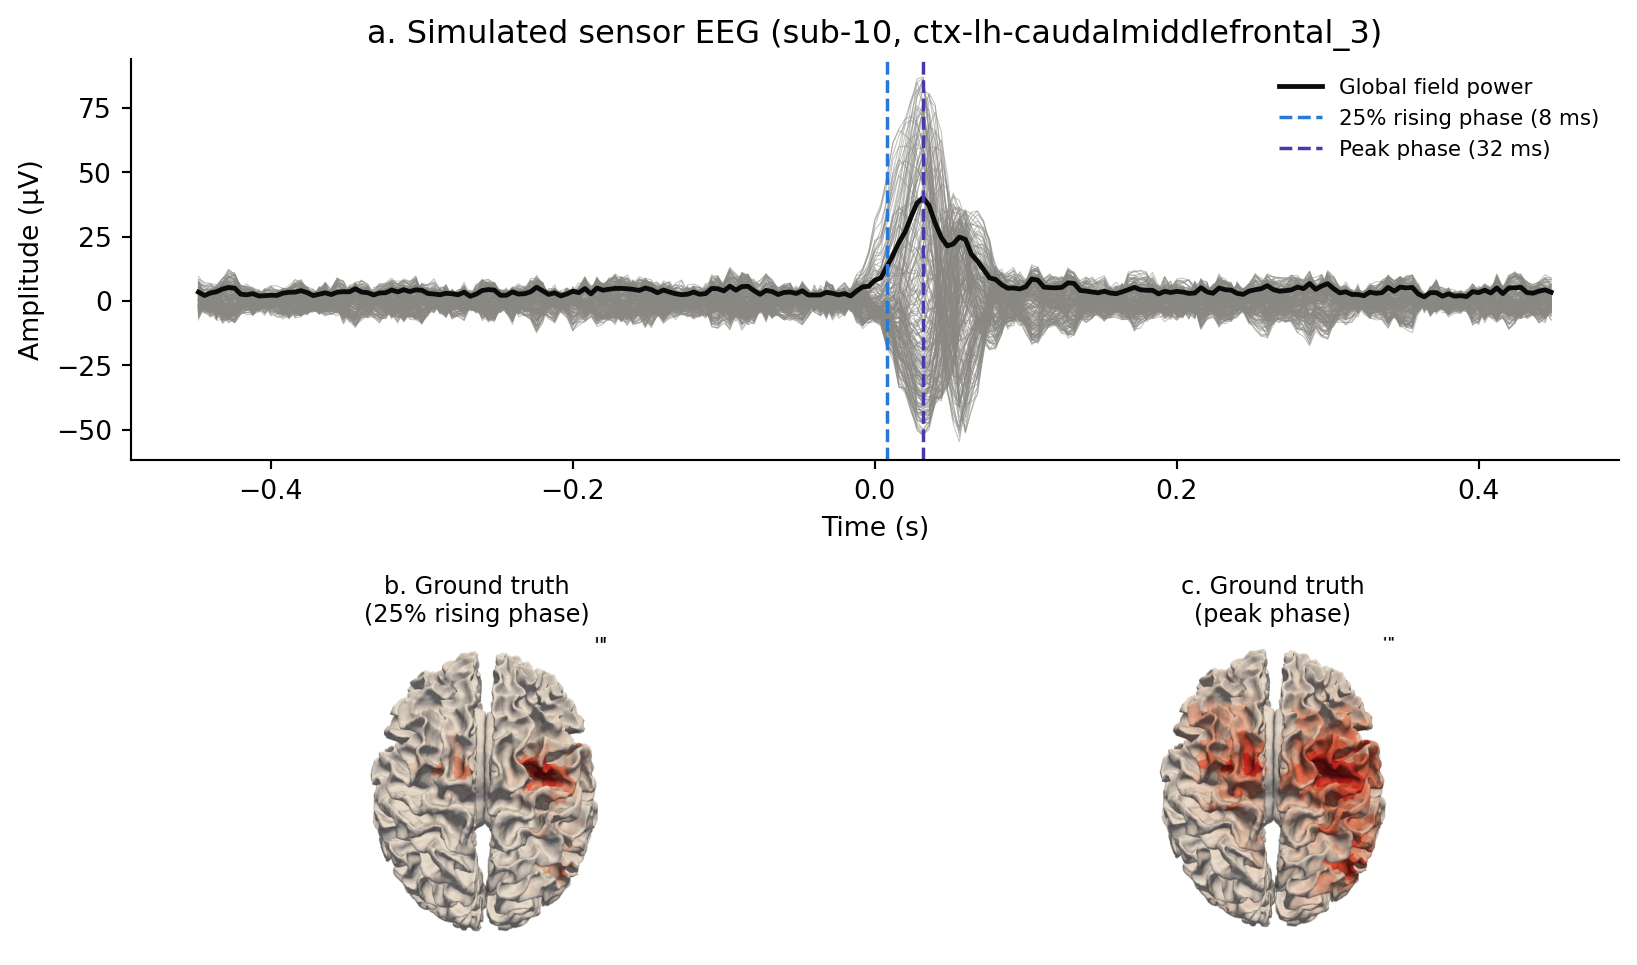

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import mindmap as mm
from scripts.data_manager import SimfManager

# Single representative simulation run from the flagship dataset (sub-10,
# original connectome, target SNR = 5) - illustrative only, not used for any
# quantitative result elsewhere in this document. qrp/pp landmarks computed
# directly on this run's own (noisy) sensor evoked, the same
# `mm.analysis.eeg.get_rising_phase` helper used throughout processing_simf.qmd.
# Source region: ctx-lh-caudalmiddlefrontal_3 (run 273, repetition 1 - see
# sub-10/simulation_index.tsv), matching the pre-rendered ground-truth brain
# images below (generated separately, not reproducible inline here).
dm = SimfManager("simf.config.yml")
sub, run = "10", 273
ave = dm.load(sub, "ave", task="spk", run=run)

qrp_idx = mm.analysis.eeg.get_rising_phase(ave, ratio=0.25, as_idx=True)[0]
pp_idx = mm.analysis.eeg.get_rising_phase(ave, ratio=1, as_idx=True)[0]
qrp_time, pp_time = ave.times[qrp_idx], ave.times[pp_idx]

data = ave.data * 1e6  # V -> uV
gfp = np.sqrt(np.mean(data ** 2, axis=0))

fig = plt.figure(figsize=(10, 6))
gs = fig.add_gridspec(2, 2, height_ratios=[1.3, 1], hspace=0.5, wspace=0.15)

ax_eeg = fig.add_subplot(gs[0, :])
ax_eeg.plot(ave.times, data.T, color=LINE_COLOR, linewidth=0.4, alpha=0.5)
ax_eeg.plot(ave.times, gfp, color="#0b0b0b", linewidth=1.8, label="Global field power")
ax_eeg.axvline(qrp_time, color=COLORS["wcset"], linestyle="--", linewidth=1.3,
               label=f"25% rising phase ({qrp_time * 1000:.0f} ms)")
ax_eeg.axvline(pp_time, color=COLORS["dspm"], linestyle="--", linewidth=1.3,
               label=f"Peak phase ({pp_time * 1000:.0f} ms)")
ax_eeg.set_xlabel("Time (s)")
ax_eeg.set_ylabel("Amplitude (μV)")
ax_eeg.set_title("a. Simulated sensor EEG (sub-10, ctx-lh-caudalmiddlefrontal_3)")
ax_eeg.legend(loc="upper right", fontsize=8, frameon=False)
ax_eeg.spines[["top", "right"]].set_visible(False)

# Ground-truth brain renders - same run/region as the EEG panel above.
# Generated separately via mm.viz.plot_brain_activity/pyvista as fixed
# images, not reproducible inline here - just embedded as-is.
brain_specs = [
    (gs[1, 0], "./results/simf/simf_example-gold-qrp.png", "b. Ground truth\n(25% rising phase)"),
    (gs[1, 1], "./results/simf/simf_example-gold-pp.png", "c. Ground truth\n(peak phase)"),
]
for grid_pos, img_path, label in brain_specs:
    ax = fig.add_subplot(grid_pos)
    ax.imshow(mpimg.imread(img_path))
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(label, fontsize=9)

plt.show()

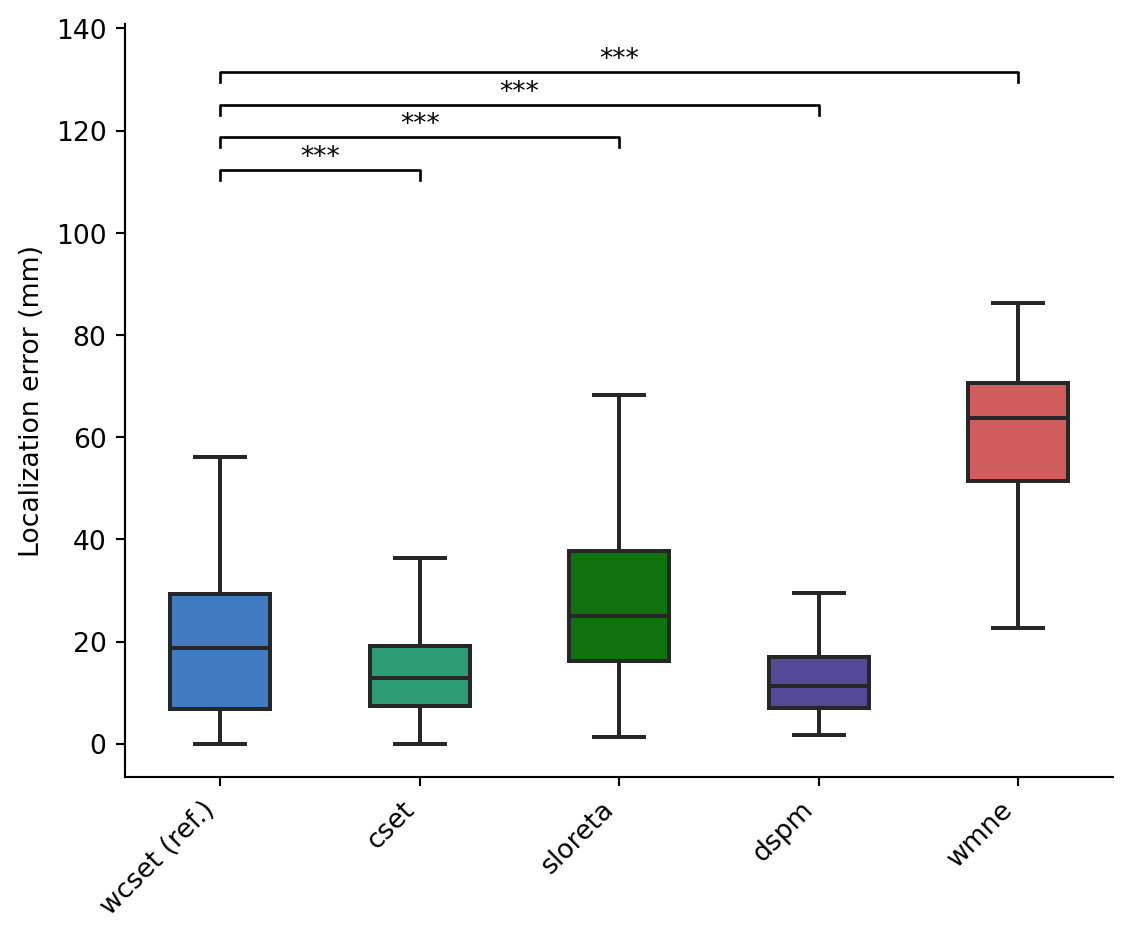

In [4]:
import matplotlib.pyplot as plt

loc1_fig, loc1_ax = plt.subplots(figsize=(6, 5))
loc1_fig, loc1_ax = simf_metrics.plot.group_comparison(
    loc1_results, order=METHODS, palette=COLORS, points=False,
    showfliers=False, width=0.5, ax=loc1_ax,
)
loc1_ax.set_xticks(range(len(METHODS)))
loc1_ax.set_xticklabels(ref_labels(METHODS, "wcset"), rotation=45, ha="right")
loc1_ax.set_xlabel("")
loc1_ax.set_ylabel("Localization error (mm)")
loc1_ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

As the source propagated beyond onset, wCSET’s advantage emerged: spatial correlation with the ground truth, tracked from the quarter rising phase through the peak (@fig-correlation-time), was significantly higher for wCSET than every competitor’s across nearly the entire displayed window (cluster-based permutation testing, region-paired, FDR-corrected), with much larger effect sizes against the three standard methods (Cohen’s dz = -6.58 for sLORETA) than against CSET (dz = -4.61), and the gap between connectivity-informed and standard methods widening toward the peak.

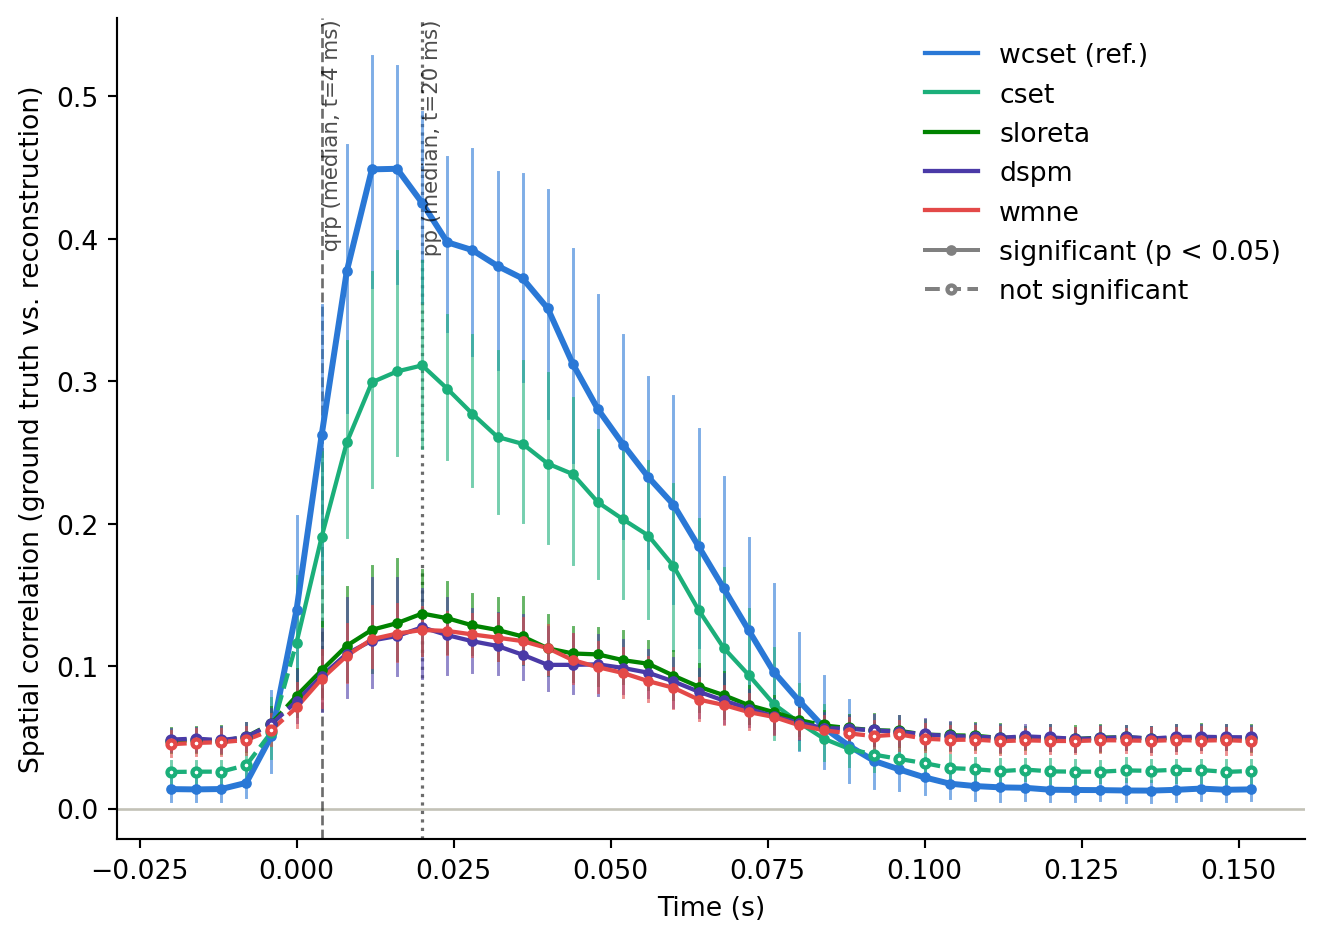

In [5]:
import matplotlib.pyplot as plt

# median quarter-rising-phase / peak time of the simulated sensor EEG, pooled
# across all runs - median again (not mean), since the same per-run spread
# checked earlier showed a heavy tail that pulls the mean noticeably off
# the typical crossing time (see conversation notes). Used only for the
# reference lines below, not quoted in the prose above.
qrp_median = simf_metrics.metadata["derived"]["qrp_time_median"]
pp_median = simf_metrics.metadata["derived"]["pp_time_median"]

corr1_fig, corr1_ax = plt.subplots(figsize=(7, 5))
corr1_fig, corr1_ax = simf_metrics.plot.cluster_permutation(
    corr1_results, colors=COLORS, marker="o", markersize=3, ax=corr1_ax,
)
mark_reference(corr1_ax, "wcset")

# qrp/pp reference lines, annotated via text rather than a legend label:
# plot.cluster_permutation() already builds its own full legend from
# synthetic proxy artists above, and a second ax.legend() call would just
# replace it outright rather than merge in these two entries (same gotcha
# fixed in simf_localization_noise.py/simf_correlation_noise.py below).
corr1_ax.axhline(0, color="#c3c2b7", linewidth=1, zorder=0)
corr1_ax.axvline(qrp_median, color="#0b0b0b", linestyle="--", linewidth=1, alpha=0.6, zorder=0.5)
corr1_ax.axvline(pp_median, color="#0b0b0b", linestyle=":", linewidth=1.2, alpha=0.6, zorder=0.5)
ymax = corr1_ax.get_ylim()[1]
corr1_ax.text(qrp_median, ymax, f" qrp (median, t={round(qrp_median*1000):.0f} ms)",
        fontsize=8, ha="left", va="top", rotation=90, alpha=0.7)
corr1_ax.text(pp_median, ymax, f" pp (median, t={round(pp_median*1000):.0f} ms)",
        fontsize=8, ha="left", va="top", rotation=90, alpha=0.7)

corr1_ax.set_xlabel("Time (s)")
corr1_ax.set_ylabel("Spatial correlation (ground truth vs. reconstruction)")
corr1_ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

### Robustness to Data Noise

Sweeping simulated target SNR from 20 down to 1 (Section 2.1.1), localization error rose for every method as SNR decreased, but wMNE degraded much earlier than the rest — the other four methods stayed low until roughly SNR=4–5 before climbing (Annex Figure 4). wCSET’s spatial-correlation advantage over every competitor, found above at fixed noise (Section 3.1.1), held across nearly the full SNR range tested, down to SNR=1 (Annex Figure 5).

### Robustness to Prior Noise

In [6]:
import mindmap as mm

deg_metrics_summary = mm.metric.MetricSuite.load("./results/simf/degradation")
_perm_d_summary = deg_metrics_summary.metadata["derived"]

# localization error (mm): wCSET's gradual rise vs. CSET's flat-then-sharp pattern
_loc_df_summary = deg_metrics_summary.to_df(metrics="localization_error", filters={"phase": "qrp"})
_loc_med_summary = _loc_df_summary.groupby(["Method", "percentage"])["Value"].median().unstack("percentage")

deg_summary_ref_loc_sloreta = fmt_num(_perm_d_summary["ref_loc"]["sloreta"])
deg_summary_loc_wcset_0 = fmt_num(_loc_med_summary.loc["wcset", 0])
deg_summary_loc_wcset_100 = fmt_num(_perm_d_summary["loc_wcset_100"])
deg_summary_loc_cset_lo_s = fmt_num(_loc_med_summary.loc["cset", 0:60].min())
deg_summary_loc_cset_hi_s = fmt_num(_loc_med_summary.loc["cset", 0:60].max())
deg_summary_loc_cset_100 = fmt_num(_loc_med_summary.loc["cset", 100])

# spatial correlation: wCSET's gradual decline vs. CSET's flat-then-sharp pattern
deg_summary_ref_corr_sloreta = fmt_num(_perm_d_summary["ref_corr"]["sloreta"], 2)
deg_summary_corr_wcset_0 = fmt_num(_perm_d_summary["corr_wcset_0"], 2)
deg_summary_corr_wcset_100 = fmt_num(_perm_d_summary["corr_wcset_100"], 2)
deg_summary_corr_cset_lo, deg_summary_corr_cset_hi = _perm_d_summary["corr_cset_0_60"]
deg_summary_corr_cset_lo_s = fmt_num(deg_summary_corr_cset_lo, 2)
deg_summary_corr_cset_hi_s = fmt_num(deg_summary_corr_cset_hi, 2)
deg_summary_corr_cset_100 = fmt_num(_perm_d_summary["corr_cset_100"], 2)

Using the connectome-perturbation procedure of Section 2.3.3, we re-evaluated localization error and spatial correlation for CSET and wCSET, benchmarked against connectome-agnostic sLORETA. For localization error (Annex Figure 6), wCSET’s error rose gradually across the full permutation range (4.4–25.8 mm from 0% to 100%), while CSET’s stayed comparatively flat through 60% (9.2–12.7 mm) before rising sharply thereafter (38.1 mm at 100%). Statistically, CSET’s early advantage over sLORETA reversed into a significant deficit once degradation passed that point; wCSET’s own error, by contrast, started well below sLORETA’s undegraded reference (14.0 mm) and only grew worse than it late in the degradation range, never by a statistically significant margin.

For spatial correlation (Annex Figure 7), the same pattern held: wCSET’s correlation with the ground truth declined gradually across the full range (0.32–0.08 from 0% to 100%), while CSET’s stayed relatively high through 60% (0.15–0.20) before dropping sharply by full permutation (0.05). CSET’s early advantage over sLORETA again reversed into a significant deficit at higher degradation; wCSET’s correlation, meanwhile, closely approached sLORETA’s own reference (0.10) by full permutation, without that difference reaching significance.

### Surrogate alternatives

In [7]:
import mindmap as mm

# beltrami replaced atlas-a2a/atlas-a2a-bin as of surrogate_reconstruction.py's
# latest run (see processing_simf.qmd) - kept in sync with the actual
# on-disk surrogate set, not the earlier atlas-a2a/-bin pair.
surrogates = ["beltrami", "fused", "fused-bin", "geom-atlas", "geom-atlas-bin"]
conditions = ["original"] + surrogates

# Reader-facing surrogate names differ from the on-disk `Surrogate` tags
# above - "fused" undersold the atlas provenance, and "geom-atlas" wrongly
# implied a population atlas (it's built purely from the subject's own
# mesh geometry) while also colliding with "geometry-only" language used
# elsewhere for the unrelated Beltrami-operator approach (Section 2.3.3).
# Data lookups/palette keys elsewhere still key off the original tags;
# only prose/inline-stat/axis text goes through this map.
SURROGATE_LABELS = {
    "fused": "atlas", "fused-bin": "atlas-bin",
    "geom-atlas": "local", "geom-atlas-bin": "local-bin",
}
methods = ["cset", "wcset"]

# Question of interest: does substituting a surrogate connectome change THIS
# method's own accuracy relative to using the real (original) connectome? -
# not whether cset differs from wcset (that's answered above, in
# simf_localization_error.py). One combined suite (original + every
# surrogate, tagged by `Surrogate`) is now built and saved by
# processing_simf.qmd's Statistics section - loaded here directly, never
# constructed ad-hoc; each panel below just filters it by `Method`/`phase`.
surr_metrics = mm.metric.MetricSuite.load("./results/simf/surrogates")
surr_comparisons = surr_metrics.stat.build_comparisons(["original"], surrogates)

# identical calls to the ones already cached by processing_simf.qmd's
# Statistics section. phase="qrp" always (no pp counterpart exists for
# this metric).
surr_loc_results = {}
for method in methods:
    surr_loc_results[method] = surr_metrics.stat.wilcoxon(
        "localization_error", group_by="Surrogate",
        comparisons=surr_comparisons, pairing_col="region",
        filters={"Method": method, "phase": "qrp"},
    )

# statistics quoted in the prose below.
def _loc_row(method, surrogate):
    return competitor_row(surr_loc_results[method], surrogate, reference="original")

loc_wcset_p = {s: fmt_p(_loc_row("wcset", s)["p_corrected"]) for s in surrogates}
loc_wcset_r = {s: fmt_stat(_loc_row("wcset", s)["effect_size"]) for s in surrogates}
_loc_wcset_r_abs = {s: abs(_loc_row("wcset", s)["effect_size"]) for s in surrogates}
loc_wcset_r_lo = fmt_stat(min(_loc_wcset_r_abs.values()))
loc_wcset_r_hi = fmt_stat(max(_loc_wcset_r_abs.values()))

# Correlation: same "original vs. surrogate" pattern, filtering the same
# combined suite by (method, phase) per panel instead of loading a separate
# pre-built suite.
surr_ref_corr = surr_metrics.metadata["derived"]["ref_corr"]

# identical calls to the ones already cached by processing_simf.qmd's
# Statistics section.
surr_corr_results = {}
for phase in ["qrp", "pp"]:
    for method in methods:
        surr_corr_results[(method, phase)] = surr_metrics.stat.wilcoxon(
            "correlation", group_by="Surrogate",
            comparisons=surr_comparisons, pairing_col="region",
            filters={"Method": method, "phase": phase},
        )

# statistics quoted in the prose below.
def _corr_row(method, phase, surrogate):
    return competitor_row(surr_corr_results[(method, phase)], surrogate, reference="original")

corr_wcset_beltrami_qrp, corr_wcset_beltrami_pp = _corr_row("wcset", "qrp", "beltrami"), _corr_row("wcset", "pp", "beltrami")
corr_wcset_beltrami_r_lo = fmt_stat(min(abs(corr_wcset_beltrami_qrp["effect_size"]), abs(corr_wcset_beltrami_pp["effect_size"])))
corr_wcset_beltrami_r_hi = fmt_stat(max(abs(corr_wcset_beltrami_qrp["effect_size"]), abs(corr_wcset_beltrami_pp["effect_size"])))

corr_wcset_beltrami_qrp_median = fmt_num(surr_metrics.metadata["derived"]["wcset_beltrami_qrp_median"], 2)
corr_wcset_beltrami_pp_median = fmt_num(surr_metrics.metadata["derived"]["wcset_beltrami_pp_median"], 2)
corr_dspm_qrp_ref = fmt_num(surr_ref_corr["qrp"]["dspm"], 2)
corr_dspm_pp_ref = fmt_num(surr_ref_corr["pp"]["dspm"], 2)
corr_sloreta_qrp_ref = fmt_num(surr_ref_corr["qrp"]["sloreta"], 2)
corr_sloreta_pp_ref = fmt_num(surr_ref_corr["pp"]["sloreta"], 2)

corr_wcset_fused_qrp, corr_wcset_fused_pp = _corr_row("wcset", "qrp", "fused"), _corr_row("wcset", "pp", "fused")
corr_wcset_fused_p_qrp, corr_wcset_fused_p_pp = fmt_p(corr_wcset_fused_qrp["p_corrected"]), fmt_p(corr_wcset_fused_pp["p_corrected"])
corr_wcset_fusedbin_qrp, corr_wcset_fusedbin_pp = _corr_row("wcset", "qrp", "fused-bin"), _corr_row("wcset", "pp", "fused-bin")
corr_wcset_fusedbin_p_qrp, corr_wcset_fusedbin_p_pp = fmt_p(corr_wcset_fusedbin_qrp["p_corrected"]), fmt_p(corr_wcset_fusedbin_pp["p_corrected"])
corr_wcset_geom_qrp, corr_wcset_geombin_qrp = _corr_row("wcset", "qrp", "geom-atlas"), _corr_row("wcset", "qrp", "geom-atlas-bin")
corr_wcset_geom_p_qrp = fmt_p(max(corr_wcset_geom_qrp["p_corrected"], corr_wcset_geombin_qrp["p_corrected"]))
corr_wcset_geom_pp, corr_wcset_geombin_pp = _corr_row("wcset", "pp", "geom-atlas"), _corr_row("wcset", "pp", "geom-atlas-bin")
corr_wcset_geom_p_pp = fmt_p(corr_wcset_geom_pp["p_corrected"])
corr_wcset_geombin_p_pp = fmt_p(corr_wcset_geombin_pp["p_corrected"])

# min/max |effect size| across all five surrogates, per phase - quoted in
# the prose below to back up the "small... to substantial" qualitative claim.
_corr_wcset_qrp_abs = [
    abs(corr_wcset_beltrami_qrp["effect_size"]), abs(corr_wcset_fused_qrp["effect_size"]),
    abs(corr_wcset_fusedbin_qrp["effect_size"]), abs(corr_wcset_geom_qrp["effect_size"]),
    abs(corr_wcset_geombin_qrp["effect_size"]),
]
corr_wcset_r_lo_qrp = fmt_stat(min(_corr_wcset_qrp_abs))
corr_wcset_r_hi_qrp = fmt_stat(max(_corr_wcset_qrp_abs))

_corr_wcset_pp_abs = [
    abs(corr_wcset_beltrami_pp["effect_size"]), abs(corr_wcset_fused_pp["effect_size"]),
    abs(corr_wcset_fusedbin_pp["effect_size"]), abs(corr_wcset_geom_pp["effect_size"]),
    abs(corr_wcset_geombin_pp["effect_size"]),
]
corr_wcset_r_lo_pp = fmt_stat(min(_corr_wcset_pp_abs))
corr_wcset_r_hi_pp = fmt_stat(max(_corr_wcset_pp_abs))

Using the dMRI-free connectome surrogates of Section 2.3.3, we tested whether they could replace the true connectome without harming CSET/wCSET’s accuracy (@fig-surrogate).

For localization error, wCSET was significantly *more* accurate using every surrogate than the true connectome, with small-to-moderate effect sizes (r = 0.22–0.49) and no surrogate meaningfully better than the others (paired Wilcoxon vs. original connectome, region-paired, all five significant: p_corrected \< 0.05). CSET showed the opposite sensitivity: beltrami and the local surrogate produced significant deficits, while the remaining three surrogates did not differ from the true connectome (full CSET breakdown in Annex Figure 8).

Spatial correlation showed the same pattern: every surrogate significantly *increased* wCSET’s correlation with the ground truth relative to the original connectome at the peak, and four of five did so at the quarter rising phase (fused-bin fell short of significance there, p_corrected = 0.093) — growing from small effect sizes at the quarter rising phase (r = 0.04–0.22) to substantial by the peak (r = 0.52–0.64), with no surrogate meaningfully better than the others, and every surrogate’s correlation remaining roughly 3–4× higher than dSPM’s or sLORETA’s own correlation with the true connectome. CSET showed the opposite pattern, generally significantly *lower* than the original connectome — consistently so for the atlas and both local surrogates (binarized and not) at both phases, and for the binarized atlas surrogate at the peak (but not at the quarter rising phase, where it fell short of significance), while never significantly different for beltrami (full CSET breakdown in Annex Figure 8).

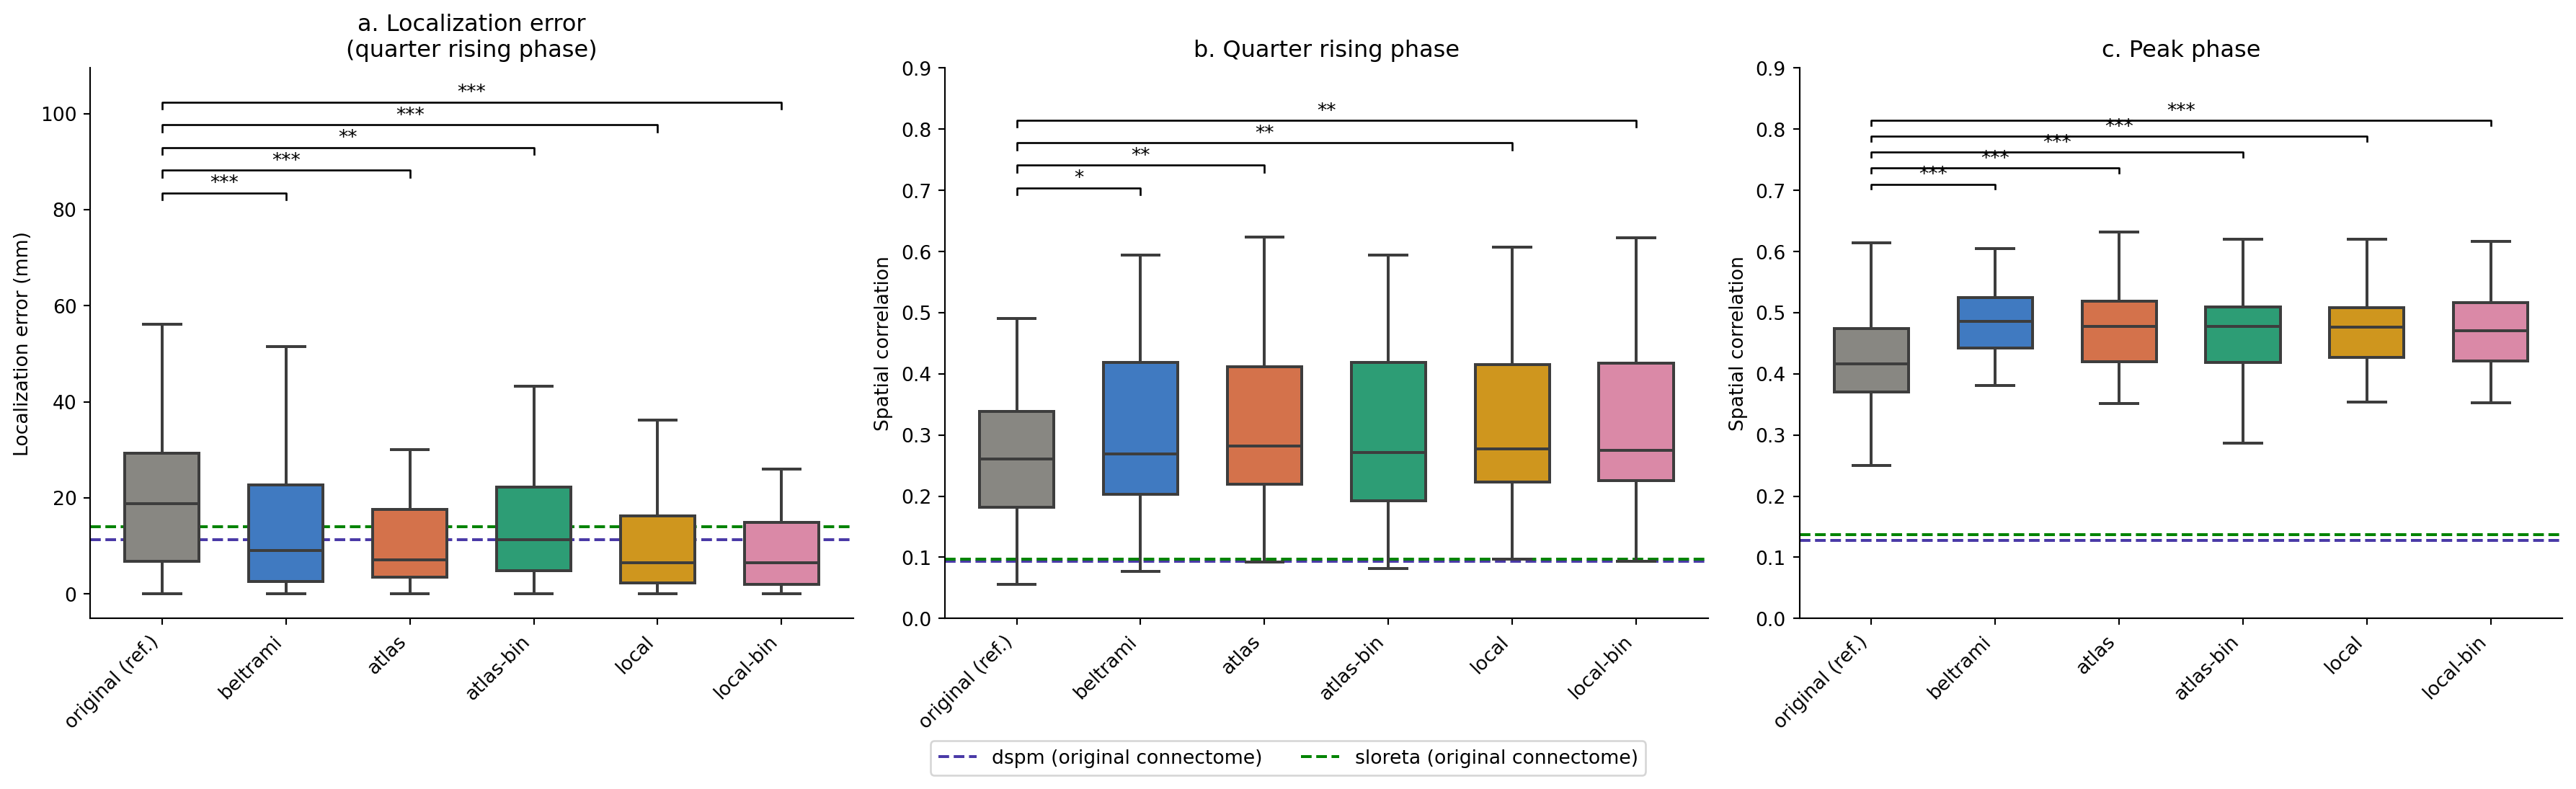

In [8]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Distinct palette from the method COLORS above - this figure's color axis is
# condition (original vs. surrogate), not method, so it needs its own key.
# "original" gets a neutral gray (the reference condition, not a "peer"
# category); surrogates get the validated categorical order (dataviz skill,
# palette.md slots 1/2/3/4/5 - blue/orange/aqua/yellow/magenta), which clears
# every adjacent-pair CVD/contrast gate in both light and dark mode.
CONDITION_COLORS = {
    "original": LINE_COLOR,
    "beltrami": "#2a78d6",
    "fused": "#eb6834",
    "fused-bin": "#1baf7a",
    "geom-atlas": "#eda100",
    "geom-atlas-bin": "#e87ba4",
}

surr_ref_loc = surr_metrics.metadata["derived"]["ref_loc"]
ref_methods = ["dspm", "sloreta"]
phase_titles = {"qrp": "Quarter rising phase", "pp": "Peak phase"}
panel_letters = {"loc": "a", "qrp": "b", "pp": "c"}

# wCSET only in the main text - CSET's equivalent panels are qualitatively
# similar (see prose) and moved to the Annex.
surr_fig, surr_axes = plt.subplots(1, 3, figsize=(len(conditions) * 1.3 * 2.4, 5.5))

# panel a: localization error at qrp.
ax_loc = surr_axes[0]
surr_fig, ax_loc = surr_metrics.plot.group_comparison(
    surr_loc_results["wcset"], order=conditions, palette=CONDITION_COLORS, points=False,
    showfliers=False, width=0.6, ax=ax_loc,
)
for ref_method in ref_methods:
    ax_loc.axhline(surr_ref_loc[ref_method], color=COLORS[ref_method], linestyle="--", linewidth=1.5, zorder=0.5)
ax_loc.set_xticks(range(len(conditions)))
ax_loc.set_xticklabels(ref_labels([SURROGATE_LABELS.get(c, c) for c in conditions], "original"), rotation=45, ha="right")
ax_loc.set_xlabel("")
ax_loc.set_ylabel("Localization error (mm)")
ax_loc.set_title(f"{panel_letters['loc']}. Localization error\n(quarter rising phase)")
ax_loc.spines[["top", "right"]].set_visible(False)

# panels b, c: spatial correlation at qrp / peak phase, sharing a y-scale.
corr_axes = {}
for phase in ["qrp", "pp"]:
    ax = surr_axes[1 if phase == "qrp" else 2]
    corr_axes[phase] = ax
    surr_fig, ax = surr_metrics.plot.group_comparison(
        surr_corr_results[("wcset", phase)], order=conditions, palette=CONDITION_COLORS, points=False,
        showfliers=False, width=0.6, ax=ax,
    )
    for ref_method in ref_methods:
        ax.axhline(surr_ref_corr[phase][ref_method], color=COLORS[ref_method], linestyle="--", linewidth=1.5, zorder=0.5)
    ax.set_xticks(range(len(conditions)))
    ax.set_xticklabels(ref_labels([SURROGATE_LABELS.get(c, c) for c in conditions], "original"), rotation=45, ha="right")
    ax.set_xlabel("")
    ax.set_ylabel("Spatial correlation")
    ax.set_title(f"{panel_letters[phase]}. {phase_titles[phase]}")
    ax.spines[["top", "right"]].set_visible(False)
for ax in corr_axes.values():
    ax.set_ylim(0, 0.9)

surr_legend_handles = [
    Line2D([0], [0], color=COLORS[m], linestyle="--", linewidth=1.5, label=f"{m} (original connectome)")
    for m in ref_methods
]
surr_fig.legend(handles=surr_legend_handles, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.04))

plt.tight_layout()

## Study II: Clinical Localization (Resection Cohort)

### Localization Error

In [9]:
import mindmap as mm

# METHODS/COLORS reused from plot_configuration.py above (same values) -
# MCE excluded from every study, see that cell's note. beltrami is added
# locally as a 6th method (RESECTION_METHODS) since it's only computed for
# the clinical cohorts, not Study I's simulation - see plot_configuration.py's
# note on METHOD_LABELS.
RESECTION_METHODS = METHODS + ["beltrami"]

# one MetricSuite for the whole cohort, built and stats-cached by
# processing_spike.qmd (resection_evaluation_metrics.py/spike_statistics.py)
# - loaded here directly, never built from a raw CSV.
resection_metrics = mm.metric.MetricSuite.load("./results/spike/resection")

# Excluded regardless of ILAE outcome - see processing_spike.qmd's Cohort
# Summary for the full breakdown (pat01: no usable resection mask AND no EEG
# channel locations; pat18: no real resection zone at all). Reproduced here
# (rather than read off the suite) so this cell's stat.wilcoxon() call below
# is byte-identical to the one processing_spike.qmd's spike_statistics.py
# already cached - without this, the call differs in its filters and silently
# recomputes over the wrong subject population instead of hitting the cache.
EXCLUDED_SUBJECTS = ["pat01", "pat18"]
all_subjects = resection_metrics.to_df(metrics="peak_distance_mm")["Subject"].unique()
included_subjects = [s for s in all_subjects if s not in EXCLUDED_SUBJECTS]

# seizure-free (ILAE=1) subjects, minus the exclusions above, quarter rising
# phase (the primary evaluation point, matching Study I's simulation cohort
# convention) - per explicit instruction, no longer faceted across every
# surgical outcome level. The suite-native replacement for a manual
# df[(df["ILAE"]==1) & ~df["Subject"].isin(EXCLUDED_SUBJECTS)] filter.
FILTERS = {"phase": "qrp", "ILAE": 1, "Subject": included_subjects}
resection_n = resection_metrics.metadata["derived"]["resection_n"]

competitors = [m for m in RESECTION_METHODS if m != "wcset"]

# box + raw per-subject points (no connecting lines) + Wilcoxon
# significance stars vs. wCSET, paired by subject, FDR-corrected.
# Identical call to the one already cached by processing_spike.qmd's
# Statistics section.
resection_results = {}
resection_results["peak_distance_mm"] = resection_metrics.stat.wilcoxon(
    "peak_distance_mm", group_by="Method",
    comparisons=resection_metrics.stat.build_comparisons(["wcset"], competitors),
    pairing_col="Subject", filters=FILTERS,
)

# statistics quoted in the prose below.
_peak = resection_results["peak_distance_mm"]

_peak_medians = resection_metrics.metadata["derived"]["peak_median"]

resection_peak_median_wcset = fmt_num(_peak_medians["wcset"])
resection_peak_median_cset = fmt_num(_peak_medians["cset"])
resection_peak_median_sloreta = fmt_num(_peak_medians["sloreta"])
resection_peak_median_dspm = fmt_num(_peak_medians["dspm"])
resection_peak_median_wmne = fmt_num(_peak_medians["wmne"])
resection_peak_median_beltrami = fmt_num(_peak_medians["beltrami"])

resection_peak_p_cset = fmt_p(competitor_row(_peak, "cset")["p_corrected"])
resection_peak_r_cset = fmt_stat(competitor_row(_peak, "cset")["effect_size"])
resection_peak_p_dspm = fmt_p(competitor_row(_peak, "dspm")["p_corrected"])
resection_peak_r_dspm = fmt_stat(competitor_row(_peak, "dspm")["effect_size"])
resection_peak_p_sloreta = fmt_p(competitor_row(_peak, "sloreta")["p_corrected"])
resection_peak_r_sloreta = fmt_stat(competitor_row(_peak, "sloreta")["effect_size"])
resection_peak_p_wmne = fmt_p(competitor_row(_peak, "wmne")["p_corrected"])
resection_peak_r_wmne = fmt_stat(competitor_row(_peak, "wmne")["effect_size"])
resection_peak_p_beltrami = fmt_p(competitor_row(_peak, "beltrami")["p_corrected"])
resection_peak_r_beltrami = fmt_stat(competitor_row(_peak, "beltrami")["effect_size"])

# smallest (i.e. closest-to-significant) corrected p-value among the four
# peak-distance comparisons that don't reach significance (all but wmne,
# see prose below) - quoted since no single one of those four is the
# natural one to single out.
_non_sig_competitors = [c for c in competitors if c != "wmne"]
resection_peak_p_min = fmt_p(min(competitor_row(_peak, c)["p_corrected"] for c in _non_sig_competitors))

Simulation offers a controlled testbed, but real clinical data will always differ. We evaluated localization accuracy against the resected epileptogenic zone in seizure-free patients (ILAE 1, n=26), alongside wMNE, sLORETA, dSPM, and the Beltrami-eigenbasis GBF variant (Section 2.4.1) as a sixth competitor.

Peak-to-resection distance was lowest for wCSET (@fig-resection-localization; median 16.4 mm), narrowly ahead of Beltrami (17.2 mm) and sLORETA (18.1 mm), then CSET (18.3 mm), with dSPM (25.5 mm) and wMNE (31.1 mm) clearly worse. Of the five paired comparisons against wCSET (Wilcoxon signed-rank, subject-paired, FDR-corrected), only wMNE reached significance (p_corrected = 0.013, r = -0.54); the rest did not, the closest being dSPM (p_corrected = 0.078).

wCSET thus matched or exceeded every competitor’s localization accuracy in real, noisier clinical data, reaching significance specifically against wMNE. This shows wCSET’s propagation-tracking advantage from Study I does not come at the cost of localization accuracy.

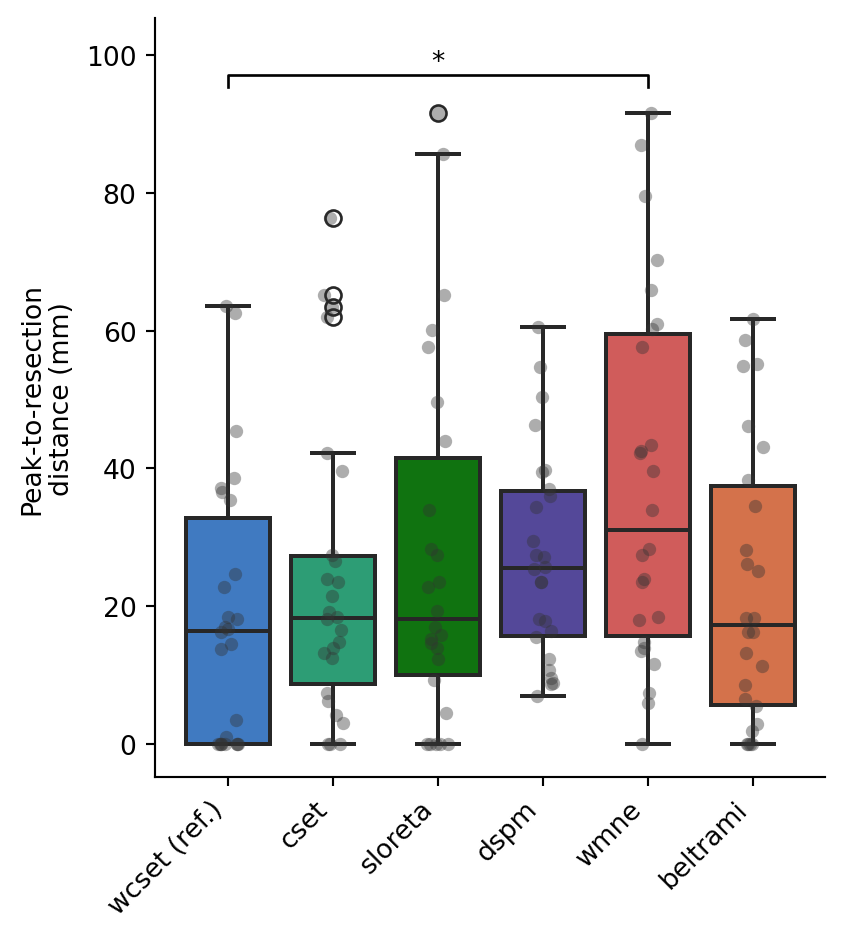

In [10]:
import matplotlib.pyplot as plt

resection_fig, resection_ax = plt.subplots(figsize=(4.5, 5))

resection_fig, resection_ax = resection_metrics.plot.group_comparison(
    resection_results["peak_distance_mm"], order=RESECTION_METHODS, palette=COLORS, points=True, ax=resection_ax,
)

resection_ax.set_xticks(range(len(RESECTION_METHODS)))
resection_ax.set_xticklabels(ref_labels(RESECTION_METHODS, "wcset"), rotation=45, ha="right")
resection_ax.set_xlabel("")
resection_ax.set_ylabel("Peak-to-resection\ndistance (mm)")
resection_ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

## Study III: Clinical Dynamics (Simultaneous iEEG/EEG)

### Spatial Correlation Analysis

As the simulation suggested, source localization in the clinical resection cohort of Study II (Section 3.2.1) yielded similar performance across methods; since connectivity-informed methods are designed to capture distributed activity rather than a single focal source, we now instead test whether they better reproduce the overall pattern of activity.

wCSET was compared against every competitor at the timepoint level (spatial correlation), via the autocorrelation-corrected paired test of Section 2.6.4.

In [11]:
import mindmap as mm

# reuses METHODS/COLORS already defined above in plot_configuration.py, so
# method colors stay consistent with every other figure in this document.
# beltrami (6th competitor, clinical-only, see plot_configuration.py's note)
# is added to COMPETITORS below in processing_intra.qmd's own method order
# (["wcset", "sloreta", "cset", "dspm", "wmne", "beltrami"]) rather than
# appended after METHODS's order, so this cell's stat.ttest_ess() calls stay
# an exact, byte-identical match to the ones already cached by that file's
# Statistics section.

# combined suite (every sub-*/ subfolder concatenated) built and stats-cached
# by processing_intra.qmd's Statistics section - loaded here directly, never
# combined via concat() in this document.
vieeg_metrics = mm.metric.MetricSuite.load("./results/intra/combined")

# Only 4 subjects total (fixed), and 2 of them (12, 50) have deep sources with
# no visible spike on scalp EEG -- their EEG-derived source reconstruction
# (and therefore virtual iEEG) starts from an inherently less reliable signal
# than 34/48's. Stats are still computed for all 4 (SUBJECT_ORDER) - reused
# by the Annex - but the main-text figure below only plots
# MAIN_SUBJECTS (34/48); 12/50 are reported in the Annex
# instead (see prose above).
SUBJECT_ORDER = ["34", "48", "12", "50"]
MAIN_SUBJECTS = ["48", "34"]
SUBJECT_TITLES = {
    "34": "Subject 2",
    "48": "Subject 1",
    "12": "sub-12\n(no visible EEG spike)",
    "50": "sub-50\n(no visible EEG spike)",
}

# Only 4 subjects - too few for subject-level pairing (pairing_col="Subject"
# would treat n=4 as the sample size, no real power). Channels/timepoints
# within one subject are numerous but NOT independent (spatially/temporally
# correlated), so a plain Wilcoxon/t-test paired across them would overstate
# significance. Fix: an autocorrelation-corrected effective sample size
# (Thiebaux & Zwiers, 1984) in place of the raw channel/timepoint count -
# mindmap.core.stats.effective_sample_size, via
# suite.stat.ttest_ess(...) - see
# mindmap/tutorials/analysis/metrics/metricsuite-intra-vieeg.ipynb, which
# this cell adapts directly (measured lag-1 autocorrelation of the
# wCSET-competitor difference series on this exact data: 0.45-0.83 for
# timepoints, 0.16-0.52 for channels - large enough that the correction has
# real bite, not just a formality).
COMPETITORS = ["sloreta", "cset", "dspm", "wmne", "beltrami"]


def paired_diffs(subject, metric, coord):
    # exact post-dropna order already computed and cached by
    # processing_intra.qmd's Statistics section - reused verbatim both to
    # rebuild this diffs array and to keep the stat.ttest_ess() call
    # below (part of the cache key) an instant cache hit rather than a
    # silent recompute under a different order.
    order = vieeg_metrics.metadata["derived"]["subject_order"][subject][metric]
    df_sub = vieeg_metrics.to_df(metrics=metric, filters={"Subject": subject})
    wide = df_sub.pivot_table(index=coord, columns="Method", values="Value", aggfunc="mean").reindex(order)
    wide = wide.dropna(subset=["wcset"] + COMPETITORS)
    return {c: (wide["wcset"] - wide[c]).to_numpy() for c in COMPETITORS}, wide.index.tolist()


METRIC_BLOCKS = [
    ("correlation_spatial", "times", "Spatial corr.\n(diff per timepoint)"),
]

# statistics quoted in the prose below and drawn by the figure at the end of
# this section are collected into these two dicts, keyed by (subject,
# metric) - so the figure and the prose numbers come from exactly the same
# stat.ttest_ess() call, run once here.
vieeg_results = {}
vieeg_diffs = {}

for metric, coord, ylabel in METRIC_BLOCKS:
    for subject in SUBJECT_ORDER:
        diffs, order = paired_diffs(subject, metric, coord)
        # identical call to the one already cached by processing_intra.qmd's
        # Statistics section.
        vieeg_results[(subject, metric)] = vieeg_metrics.stat.ttest_ess(
            metric, group_by="Method", comparisons=vieeg_metrics.stat.build_comparisons(["wcset"], COMPETITORS),
            pairing_col=coord, subject_order=order, filters={"Subject": subject},
        )
        vieeg_diffs[(subject, metric)] = diffs

# statistics quoted in the prose below.
def _p(subject, metric, competitor):
    return competitor_row(vieeg_results[(subject, metric)], competitor)["p_corrected"]

def _neff(subject, metric, competitor):
    return competitor_row(vieeg_results[(subject, metric)], competitor)["n_eff"]

def _winrate(subject, metric, competitor):
    return vieeg_metrics.metadata["derived"]["win_rate"][f"{subject}|{metric}|{competitor}"]

def _dz(subject, metric, competitor):
    # ttest_ess's own effect size (Cohen's dz on the wcset-competitor
    # difference series) - positive means wCSET wins, matching the
    # win-rate/diff sign convention used elsewhere in this cell.
    return competitor_row(vieeg_results[(subject, metric)], competitor)["effect_size"]

vieeg_48_spatial_p_cset = fmt_p(_p("48", "correlation_spatial", "cset"))
vieeg_48_spatial_p_sloreta = fmt_p(_p("48", "correlation_spatial", "sloreta"))
vieeg_48_spatial_p_dspm = fmt_p(_p("48", "correlation_spatial", "dspm"))
vieeg_48_spatial_p_wmne = fmt_p(_p("48", "correlation_spatial", "wmne"))
vieeg_48_spatial_p_beltrami = fmt_p(_p("48", "correlation_spatial", "beltrami"))
vieeg_48_spatial_neff_cset = f"{_neff('48', 'correlation_spatial', 'cset'):.0f}"
vieeg_48_spatial_neff_sloreta = f"{_neff('48', 'correlation_spatial', 'sloreta'):.0f}"
vieeg_48_spatial_neff_dspm = f"{_neff('48', 'correlation_spatial', 'dspm'):.0f}"
vieeg_48_spatial_neff_wmne = f"{_neff('48', 'correlation_spatial', 'wmne'):.0f}"
vieeg_48_spatial_neff_beltrami = f"{_neff('48', 'correlation_spatial', 'beltrami'):.0f}"
vieeg_48_spatial_dz_cset = fmt_stat(_dz("48", "correlation_spatial", "cset"))
vieeg_48_spatial_dz_sloreta = fmt_stat(_dz("48", "correlation_spatial", "sloreta"))
vieeg_48_spatial_dz_dspm = fmt_stat(_dz("48", "correlation_spatial", "dspm"))
vieeg_48_spatial_dz_wmne = fmt_stat(_dz("48", "correlation_spatial", "wmne"))
vieeg_48_spatial_dz_beltrami = fmt_stat(_dz("48", "correlation_spatial", "beltrami"))

# min/max across the four uniform-direction competitors (cset/sloreta/dspm/wmne),
# for the compressed range quoted in prose - beltrami excluded (opposite direction).
_vieeg_48_spatial_dz4 = [_dz("48", "correlation_spatial", c) for c in ["cset", "sloreta", "dspm", "wmne"]]
vieeg_48_spatial_dz4_lo = fmt_stat(min(_vieeg_48_spatial_dz4))
vieeg_48_spatial_dz4_hi = fmt_stat(max(_vieeg_48_spatial_dz4))
_vieeg_48_spatial_neff4 = [_neff("48", "correlation_spatial", c) for c in ["cset", "sloreta", "dspm", "wmne"]]
vieeg_48_spatial_neff4_lo = f"{min(_vieeg_48_spatial_neff4):.0f}"
vieeg_48_spatial_neff4_hi = f"{max(_vieeg_48_spatial_neff4):.0f}"
_vieeg_48_spatial_p4 = [_p("48", "correlation_spatial", c) for c in ["cset", "sloreta", "dspm", "wmne"]]
vieeg_48_spatial_p4_max = fmt_p(max(_vieeg_48_spatial_p4))

# excludes beltrami deliberately: its raw per-timepoint win-rate sits below
# chance (unlike the other four), even though the autocorrelation-corrected
# paired test below does not find this difference significant - folding it
# into this range would make the "above chance" framing wrong either way.
# Reported separately in the prose instead.
_sub48_spatial_winrates = [_winrate("48", "correlation_spatial", c) for c in ["cset", "sloreta", "dspm", "wmne"]]
vieeg_48_winrate_min = f"{min(_sub48_spatial_winrates) * 100:.0f}"
vieeg_48_winrate_max = f"{max(_sub48_spatial_winrates) * 100:.0f}"
vieeg_48_winrate_pp_min = f"{(min(_sub48_spatial_winrates) - 0.5) * 100:.0f}"
vieeg_48_winrate_pp_max = f"{(max(_sub48_spatial_winrates) - 0.5) * 100:.0f}"
vieeg_48_beltrami_winrate = f"{_winrate('48', 'correlation_spatial', 'beltrami') * 100:.0f}"

Among the subjects with a visible EEG spike, the two responded very differently (@fig-intracranial-diff). Subject 1 showed the clearest advantage for wCSET: spatial correlation was significantly higher than sLORETA, dSPM, wMNE, and CSET alike, with wCSET winning 62–74% of timepoints against these four competitors. Against Beltrami the pattern reversed but did not reach significance (p_corrected = 0.074): wCSET won only 48% of individual timepoints, below the 50% chance level, but the difference was not statistically robust.

Subject 2 did not reproduce this pattern: wCSET’s spatial correlation did not differ significantly from any competitor.

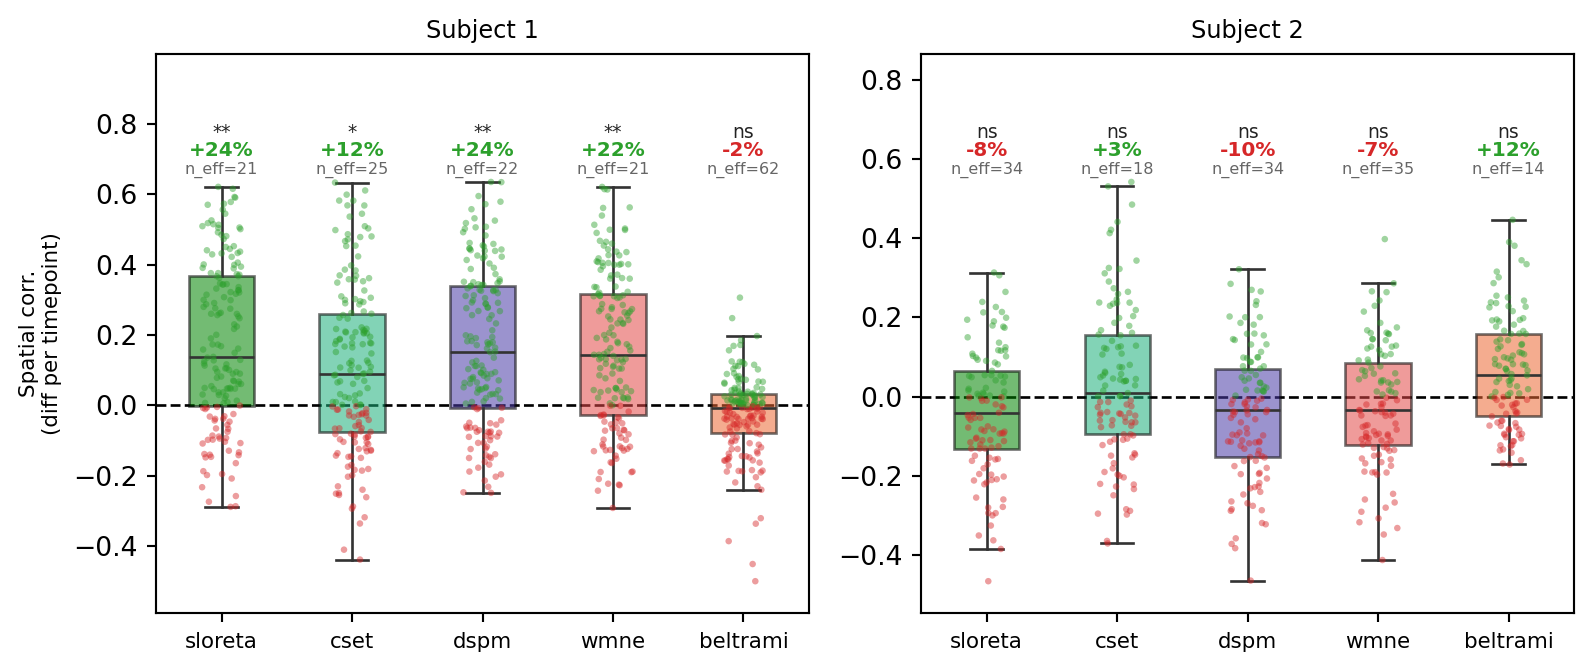

In [12]:
import numpy as np
import matplotlib.pyplot as plt


def draw_diff_panel(ax, subject, metric, coord, title=None):
    diffs = vieeg_diffs[(subject, metric)]
    results = vieeg_results[(subject, metric)]

    data = [diffs[c] for c in COMPETITORS]
    bp = ax.boxplot(data, positions=range(len(COMPETITORS)), widths=0.5,
                     patch_artist=True, showfliers=False, zorder=2)
    for patch, c in zip(bp["boxes"], COMPETITORS):
        patch.set_facecolor(COLORS[c])
        patch.set_alpha(0.55)
    for element in ["whiskers", "caps", "medians"]:
        for line in bp[element]:
            line.set_color("#333333")

    rng = np.random.default_rng(0)
    for i, c in enumerate(COMPETITORS):
        y = diffs[c]
        x = i + rng.uniform(-0.15, 0.15, size=len(y))
        point_colors = np.where(y > 0, "tab:green", "tab:red")
        ax.scatter(x, y, s=6, alpha=0.45, c=point_colors, linewidths=0, zorder=3)

    ax.axhline(0, color="black", linewidth=1, linestyle="--", zorder=1)
    ax.set_xticks(range(len(COMPETITORS)))
    ax.set_xticklabels(COMPETITORS, fontsize=8)

    ymax, ymin = max(np.max(d) for d in data), min(np.min(d) for d in data)
    span = ymax - ymin
    for i, c in enumerate(COMPETITORS):
        row = competitor_row(results, c)
        # relative to the 50% chance line, not the raw win-rate - +17%/-13%
        # reads instantly (sign+color = direction, magnitude = how far from
        # a coin flip), where "37% vs. 67%" both need mentally subtracting
        # 50% first to compare. Read from processing_intra.qmd's precomputed
        # metadata["derived"], not recomputed here (a genuine derived stat).
        rel_win = vieeg_metrics.metadata["derived"]["win_rate"][f"{subject}|{metric}|{c}"] - 0.5
        p = row["p_corrected"]
        stars = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"
        win_color = "tab:green" if rel_win > 0 else "tab:red"
        ax.text(i, ymax + 0.10 * span, stars, ha="center", va="bottom", fontsize=7, color="#222222")
        ax.text(i, ymax + 0.055 * span, f"{rel_win:+.0%}", ha="center", va="bottom",
                fontsize=7.5, color=win_color, fontweight="bold")
        ax.text(i, ymax + 0.01 * span, f"n_eff={row['n_eff']:.0f}", ha="center", va="bottom",
                fontsize=6, color="#666666")

    ax.set_ylim(ymin - 0.08 * span, ymax + 0.32 * span)
    if title:
        ax.set_title(title, fontsize=9)


# MAIN_SUBJECTS only (34/48) - sub-12/sub-50 (no visible EEG spike) are
# reported in the Annex instead (see prose above).
vieeg_fig, vieeg_axes = plt.subplots(
    len(METRIC_BLOCKS), len(MAIN_SUBJECTS),
    figsize=(4.2 * len(MAIN_SUBJECTS), 3.6 * len(METRIC_BLOCKS)),
    squeeze=False,
)

for row_i, (metric, coord, ylabel) in enumerate(METRIC_BLOCKS):
    for col_i, subject in enumerate(MAIN_SUBJECTS):
        ax = vieeg_axes[row_i, col_i]
        draw_diff_panel(ax, subject, metric, coord, title=SUBJECT_TITLES[subject] if row_i == 0 else None)
        if col_i == 0:
            ax.set_ylabel(ylabel, fontsize=8)

plt.tight_layout()

# Discussion

## Simulation Insights

Our connectome-driven propagation model lets a focal source recruit distant regions directly through long-range tracts rather than only spreading through neighbors step by step — a mechanism unavailable to nearest-neighbor spread, and impractical to reproduce with neural mass models at realistic dipole counts \[@sanz-leon_mathematical_2015; @nunez_multi-scale_2019\] (design rationale in Annex). Because the scalp signal sums every active dipole while the source’s own amplitude decays with distance from the origin, the EEG peak systematically lags true onset — consistent with the clinical literature on interictal discharge propagation \[@vorderwulbecke_high-density_2020; @carboni_linear_2022\], and the reason the field favors an earlier point in the rising phase for localization over the peak.

At that early, focal quarter-rising-phase point, wCSET localized about as accurately as CSET and dSPM and clearly outperformed wMNE, with a more modest advantage over sLORETA; with 100 regions behind each comparison, effect sizes rather than p-values separate these meaningful and negligible gaps. This is expected: connectivity information should help least while a source is still genuinely focal. Its role becomes clear once the source spreads: spatial correlation with ground truth improves for every method toward the peak, but far more for wCSET and CSET, consistent with the connectome-spectrum representation becoming more compact as activity spreads across the cortex \[@rue-queralt_connectome_2021\]. This advantage held broadly across single-trial SNR, and, under connectome degradation, wCSET’s edge over sLORETA never reversed even under full (100%) edge permutation, unlike CSET’s, which reversed into a deficit beyond 80% — a reassuring margin given how much false-positive structure real tractography can contain \[@maier-hein_challenge_2017\]. This robustness also guided wCSET’s own design: an initial attempt to weight harmonics by robustness to perturbation itself \[@sipes_integrative_2024\] favored both very low- and very high-frequency harmonics, but the latter introduced reconstruction artifacts, leaving the smooth, low-frequency-favoring exponential decay that became wCSET.

That tolerance extended to a more radical test: substituting the true connectome for cheap, dMRI-free surrogates — an atlas prior, a local-geometry rule, or Laplace-Beltrami eigenmodes — left wCSET’s accuracy unchanged or slightly improved, with binarized and weighted variants performing almost identically, indicating the benefit rests on topology rather than precise edge weights.

We hypothesize the true connectome’s underperformance relative to its surrogates comes down to how spatially concentrated each connectome’s harmonics are (inverse participation ratio; Annex Figure 1). The true connectome’s harmonics cluster tightly on small, sometimes disjoint groups of dipoles, while the surrogates’ harmonics spread more uniformly across the cortex. Because wCSET’s weighting forces the reconstruction to lean on these harmonics, a tightly clustered harmonic is a strong, specific bet: it pays off when the signal is clustered similarly, but backfires when the signal is elsewhere — the same trade-off behind the reconstruction artifacts from very high-frequency (most spatially focal) harmonics noted above.

What matters may be less whether a connectome is anatomically *true* than whether its harmonics are spatially homogeneous — explaining why a purely geometric surrogate like Beltrami, which discards white matter connectivity entirely, still reconstructs well: its harmonics are meaningfully less localized than the true connectome’s. This points to a specific limitation in how wCSET uses connectivity, not a shortcoming of connectivity information itself: its harmonic weighting has no way to tell whether a cluster it leans on reflects genuinely correlated activity, or is just an artifact of the graph’s structure. CSET shows no comparable benefit from these surrogates, consistent with this account: its adaptive, $l_1$-sparse selection of harmonics, rather than wCSET’s fixed weighting, means it is never forced to rely on any one harmonic’s localization, so it has nothing to be rescued from.

## Epilepsy with Resected Ground Truth

The resection cohort reproduced the simulation’s localization picture almost exactly: wCSET’s peak-to-resection distance was the lowest of the six methods and did not differ significantly from CSET, sLORETA, dSPM, or Beltrami, while it was significantly lower than wMNE’s — the one method wCSET had also clearly outperformed in simulation. Using the same resection cohort, @wang_geometry_2026 report an almost identical pattern for their geometry-only GBF method: a significant improvement over MNE (P = 0.012), but no significant advantage over dSPM, sLORETA, or eLORETA (P = 0.079–0.133) — the same specific edge over (w)MNE, and the same parity with the rest, that we find for wCSET. However, localization error was considerably worse here than in simulation. Two explanations seem most likely, and aren’t mutually exclusive: our simulated noise model may underestimate real physiological noise, or propagation may already be underway by the quarter rising phase in real spikes, so some of that early spread gets captured despite our timing choice. We included this cohort because localization against a resected ground truth is how the field conventionally validates these methods, and we wanted to confirm wCSET does not perform worse in this more realistic, noisier scenario: its connectivity-informed prior did not trade away localization accuracy for its propagation-tracking advantage — if anything, it gained a real edge over one of the three connectivity-agnostic baselines, without giving ground to any of the others.

## Epilepsy with Intracranial Electrodes

As in simulation, we expected wCSET’s overall spatial-correlation advantage over standard methods to be higher. Real intracranial recordings confirmed this in one of the two evaluable subjects with a scalp-visible spike, but not the other. In the first, wCSET significantly outperformed sLORETA, dSPM, wMNE, and CSET. In the second, it matched every one of them. In neither subject did wCSET perform significantly worse than any competitor: it was always as good, or substantially better.

Against Beltrami, neither method came out significantly ahead in either subject. This parity, not a loss, is further evidence that a purely geometric account can rival a connectome-informed one. Using resected epileptogenic zones as ground truth in 20 drug-resistant epilepsy patients, @siu_structural_2026 found the same parity: geometric and connectome eigenmodes performed comparably, with geometric eigenmodes showing only a modest edge in recall.

The remaining two subjects had deep sources invisible on scalp EEG, where no method reconstructed the intracranial signal well. @grova_intracranial_2016 report the same limitation. This is consistent with our framework’s reliance on a fixed-orientation, cortically-constrained source model, which cannot properly represent deeper generators. Extending it to such sources would require encoding source orientation within the connectivity structure itself, which we leave for future work.

## Limitations

Our source model has a structural limitation: dipoles are restricted to a fixed-orientation, cortically-constrained grid (Section 2.3.1), which excludes deep, subcortical generators entirely. This is a missed opportunity, since tractography, the very data our connectivity prior draws on, also encodes connections to and among deep structures. Relatedly, our surrogate and binarization results (Section 3.1.4) suggest wCSET currently draws its benefit mostly from connectome topology rather than precise edge weights, so the richer, weighted connectivity information remains largely unexploited.

We also restricted our standard baselines to methods available in MNE-Python. This excludes LORETA and LAURA, the two algorithms @carboni_linear_2022 found most accurate for interictal-discharge localization, outperforming sLORETA, eLORETA. It also excludes beamformer methods entirely. A more complete comparison against these alternatives is left for future work.

Our simulation also idealizes several aspects of real recordings: it assumes known conductivities, is built around a single representative subject, and uses propagation and noise models that, while physiologically motivated, remain simplified. Many of its parameters were fixed rather than systematically swept, and some of the effect sizes we report are small enough that different choices could plausibly shift specific comparisons. We remain confident in the broader pattern: spatial correlation improves more for wCSET as a source spreads. But that confidence is only as strong as the simulation’s own modeling choices, which may still deviate from real cortical dynamics in ways we cannot yet quantify.

Finally, the intracranial cohort’s evaluable sample (two subjects with a scalp-visible spike) is too small to draw firm conclusions from. Even after correcting each subject’s own effective sample size for autocorrelation across channels and timepoints, this precludes any statistical test across independent subjects. More subjects are needed before we can be confident these patterns generalize.

# Conclusion

Source reconstruction is conventionally benchmarked on localizing a single, focal generator, a criterion that says little about a method’s ability to capture distributed, network-level dynamics. We hypothesized connectivity-informed approaches would be better suited to this, and introduced wCSET, a smooth, exponentially decaying L2 prior over the connectome-harmonic spectrum, to test it directly. We validated wCSET, alongside CSET, three connectivity-agnostic methods, and a geometry-based (Laplace-Beltrami) alternative, against three independent ground truths spanning a source’s onset and its distributed activity: simulated connectome propagation, a resected epileptogenic zone, and simultaneous intracranial recordings.

wCSET matched standard methods at localizing a source’s onset, including a significant edge over wMNE specifically in both simulation and the resection cohort. It reconstructed the source’s subsequent spread substantially better wherever we could test it directly, beating every connectivity-agnostic method and CSET in simulation, and standard methods and CSET in one of two evaluable intracranial subjects. This advantage held under sensor noise, substantial connectome degradation, and when the true connectome was replaced by simple, dMRI-free surrogates, indicating it rests on coarse, large-scale structure rather than precise individual tractography. The clearest exception was Beltrami: a purely geometric alternative that tracked wCSET’s performance throughout and matched it in the resection cohort and against real intracranial recordings, a pattern two independent groups reported in their own geometry-versus-connectome comparisons.

Beyond wCSET itself, we see the three-part validation framework as this work’s more durable contribution: simulated, resected, and intracranial ground truths that jointly probe a source’s full activity pattern rather than its onset alone. Two pieces of it stand on their own: a connectome-driven propagation simulation that models network-level spread directly in dipole space rather than growing a single patch, and simultaneous EEG/iEEG recordings that validate reconstruction beyond localization entirely. Extending both to future connectivity- and geometry-informed methods, and to source models representing deep and multi-generator activity, are natural next steps toward source imaging that reflects the brain’s network organization rather than collapsing it back to a single point.

# Acknowledgements

This work was supported by the Swiss National Science Foundation (SNF) under grant number 209470.

# Generative AI Disclosure

During the preparation of this manuscript, the author(s) used Claude (Anthropic) to assist with rewriting and editing portions of the text for clarity and concision. All AI-generated or AI-edited content was reviewed, verified, and edited by the author(s), who take full responsibility for the accuracy and integrity of the published work.

# Data and Code Availability

Code for the analyses and figures presented in this manuscript is available at \[manuscript repository link\], with the accompanying `mindmap` analysis package available at \[mindmap package repository link\].

The simulated data used in Study I (Section 2.1.1) can be regenerated using this code together with the publicly available VEPCON anatomical dataset \[@pascucci_source_2022\]. The resection cohort used in Study II (Clinical Dataset A) is publicly available; see @vorderwulbecke_high-density_2025 for access details. The simultaneous EEG/iEEG dataset used in Study III (Clinical Dataset B) is not yet publicly available; access arrangements will be determined at a later stage.

# Annex

Extended methodological detail, full statistical results, and supplementary figures and tables are provided in a separate document: [Annex](annex/annex.html).